<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">
<br>
<h1 style="font-family:verdana; font-size:26px"><center>~ Data Science Competition FIK FAIR 2026: Prediksi Anonymous Competition Score ~</center></h1>
<h3 style="font-family:verdana; font-size:14px; color:gray"><center>Foundation model tabular, informasi urutan baris, dan koreksi residual bertingkat</center></h3>
<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# **NAMA TIM**

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Isi

1. [**Pendahuluan**](#1)
2. [**Inisialisasi**](#2)
3. [**Analisis Data Eksploratif**](#3)
4. [**Prapemrosesan dan Rekayasa Fitur**](#4)
5. [**Skema Validasi**](#5)
6. [**Pemodelan**](#6)
7. [**Inferensi dan Submisi**](#7)
8. [**Dashboard Solusi**](#8)
9. [**Pasca-Analisis**](#9)
10. [**Daftar Pustaka**](#10)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pendahuluan <a name="1"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Kompetisi

Pada **Data Science Competition FIK FAIR 2026**, peserta diminta memprediksi *Anonymous Competition Score*, sebuah skor komposit yang rumusnya dirahasiakan panitia. Setiap observasi hanya dideskripsikan oleh 24 fitur numerik anonim yang berasal dari indikator lingkungan dan iklim, lalu ditransformasi berlapis (normalisasi rank, transformasi terbatas, proyeksi linear privat, standardisasi, perturbasi terkontrol, dan pembulatan). Akibatnya, fitur tidak memiliki satuan maupun makna fisik yang dapat ditafsirkan secara langsung.

- **Tugas**: regresi tabular, satu nilai kontinu per `record_id`
- **Data**: 382 baris *train* berlabel, 96 baris *test*, 24 fitur
- **Metrik**: *Root Mean Squared Error* (RMSE), MAE sebagai *tie-breaker*
- **Leaderboard**: *public* sekitar 30% *test* (+/-29 baris), *private* sekitar 70% (+/-67 baris)
- **Platform**: Kaggle Notebook, GPU T4 x2 (hanya untuk mode `FULL`)

---

## Dataset

*Dataset* resmi terdiri dari `train.csv` (fitur dan `target`), `test.csv` (fitur saja), dan `submission_template.csv`. Kolom `record_id` adalah ID teknis yang diacak dan tidak membawa makna geografis. Fitur `feature_01` sampai `feature_24` bersifat tanpa dimensi dan disimpan dengan enam angka desimal. Target bernilai kontinu sekitar 32,6 sampai 100,4.

Dengan hanya 382 baris berlabel, risiko terbesar kompetisi ini bukan kekurangan model, melainkan *overfitting*, validasi yang terlalu optimis, dan godaan mengejar skor *public* yang hanya dihitung dari sekitar 29 baris.

---

## Metrik

RMSE mengukur besar galat tipikal dalam satuan target. Karena galat dikuadratkan, sedikit baris dengan galat besar mendominasi skor, sehingga ekor kanan target (skor di atas 70) menjadi perhatian utama sepanjang analisis.

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(y_i - \hat{y}_i\right)^2}$$

---

## Pendekatan: *Foundation Model* + Urutan Baris + Koreksi Residual Bertingkat

Solusi akhir tersusun dari tiga lapisan. **Lapisan fitur** memprediksi skor hanya dari 24 fitur menggunakan *tabular foundation model* TabICLv2 dan TabPFN-3.5 (prediksi lewat *in-context learning*, tanpa *training* gradien pada data kompetisi) serta SVR RBF pada beberapa *view* PCA. Ketiganya memakai *pseudo-labelling* transduktif.

**Lapisan urutan** memanfaatkan temuan EDA bahwa baris pada kedua berkas tersusun menurut target. Penggunaan urutan baris ini telah dikonfirmasi panitia sebagai bagian dari EDA dan prapemrosesan peserta (4 Oktober 2026). **Lapisan koreksi** memperbaiki posisi relatif tiap baris *test* dan memodelkan penyimpangan lokal target dari urutannya melalui empat tahap bersarang.

```
24 fitur mentah
    |
    +-- TabICLv2 (norm=none, 4 seed) + pseudo-label  --+
    +-- TabPFN-3.5 + pseudo-label                     --+-- rata-rata = FM-PL-mean
    +-- PCA(10..20) whitened -> SVR plateau + pseudo-label = SVR-plateau-PL
         |
    prediksi fitur = 0.7 FM-PL-mean + 0.3 SVR-plateau-PL          (lapisan fitur)
         |
    v9  = rata-rata(peta kuantil posisi, prediksi fitur terurut)  (lapisan urutan)
    v10 = 0.5 v9  + 0.5 koreksi rank dari tetangga PCA-12         (lapisan koreksi)
    v11 = 0.5 v10 + 0.5 Ridge pada residual fitur ter-detrend
    v12 = 0.5 v11 + 0.5 detrend local-linear + interaksi posisi
    v13 = 0.5 v12 + 0.5 Kernel Ridge RBF pada residual  -> submisi
```

Seluruh tahap memakai satu skema *repeated 5-fold* (3 *repeat*) yang sama. Setiap pemilihan kandidat di dalam tahap dilakukan dengan *inner cross-validation* pada baris *train* luar saja, dan bobot 50:50 ditetapkan sebelum evaluasi, sehingga estimasi RMSE di setiap tahap tetap jujur.

---

## Perjalanan Solusi

Solusi dikembangkan dalam 13 iterasi. Tabel berikut merangkum iterasi yang mengubah model. Skor *public* hanya dicatat sebagai pemeriksaan arah, tidak pernah dipakai untuk memilih parameter.

| Versi | Perubahan utama | RMSE CV | RMSE *public* |
|---|---|---:|---:|
| v1 | TabICLv2 + SVR multi-PCA, *blend* NNLS | 7,41 | 7,947 |
| v2 | TabICLv2 tanpa normalisasi *power*, *bagging* 4 seed | 7,40 | 7,902 |
| v3 | *Pseudo-labelling* transduktif TabICLv2 | 7,32 | 7,888 |
| v5 | Rata-rata TabICLv2-PL dan TabPFN-3.5-PL | 7,30 | 7,888 |
| v6b | SVR *plateau* dengan *clipping* rentang target | 7,26 | 7,837 |
| v8 | *Pseudo-labelling* untuk SVR | 7,23 | 7,900 |
| v9 | Pemetaan urutan baris | 3,613 | 2,387 |
| v10 | Koreksi rank dari tetangga fitur | 3,401 | 2,107 |
| v11 | Ridge pada residual fitur ter-*detrend* | 3,303 | 1,955 |
| v12 | *Detrend local-linear* + interaksi posisi | 3,179 | 1,825 |
| **v13** | ***Kernel Ridge* pada residual (final)** | **3,016** | - |

RMSE CV v1 sampai v8 adalah RMSE *blend nested*, sedangkan mulai v9 adalah rata-rata RMSE 15 *fold* luar. Kedua estimand tidak dapat dibandingkan secara langsung, namun lompatan dari sekitar 7,2 ke 3,6 jauh melampaui perbedaan estimand. Notebook ini menghitung ulang seluruh angka v9 sampai v13.

---

## Referensi Utama

- `docs/eda_findings.md` -- catatan seluruh eksperimen v1 sampai v9, termasuk ide yang ditolak
- `docs/v10_order_refinement.md` sampai `docs/v13_deep_analysis.md` -- analisis dan validasi tahap koreksi
- `eda/` -- *script* analisis yang mencetak angka dan menyimpan grafik untuk setiap iterasi

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inisialisasi <a name="2"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Environment

In [1]:
!nvidia-smi

> Catatan untuk juri dan panitia: notebook berjalan dalam mode `INFERENCE` secara bawaan. Mode ini memuat keluaran lapisan fitur (TabICLv2, TabPFN-3.5, SVR) dari *run* GPU Kaggle yang dibekukan pada dataset `fikfair-artifacts`, lalu menjalankan seluruh analisis, lapisan urutan, dan keempat tahap koreksi di CPU dalam beberapa menit. Hasilnya diverifikasi identik dengan `submission_v13.csv` yang disubmit. Mode `FULL` melatih ulang lapisan fitur di dua GPU T4 dan membutuhkan token Prior Labs.

---

## Instalasi

Baris berikut memasang pustaka *foundation model* yang hanya dibutuhkan pada mode `FULL`. Pada mode `INFERENCE`, kegagalan instalasi (misalnya tanpa internet) tidak memengaruhi hasil.

In [2]:
%pip install -q tabicl tabpfn

---

## Pustaka

Seluruh impor dikelompokkan dalam satu sel agar mudah ditelusuri. NumPy, pandas, SciPy, dan scikit-learn menjalankan seluruh analisis dan tahap koreksi, sedangkan PyTorch, TabICL, dan TabPFN hanya diperlukan untuk melatih ulang lapisan fitur sehingga impornya dibuat opsional.

In [3]:
import hashlib
import io
import os
import platform
import random
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec
from scipy import stats
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.ndimage import gaussian_filter1d
from scipy.spatial.distance import cdist, pdist
from scipy.special import betainc
from sklearn.compose import TransformedTargetRegressor
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import Ridge
from sklearn.metrics import roc_auc_score
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import KFold, RepeatedKFold, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from statsmodels.nonparametric.smoothers_lowess import lowess

try:
    import torch
    from tabicl import TabICLRegressor
    from tabpfn import TabPFNRegressor
    from tabpfn.constants import ModelVersion
except ImportError:
    torch = TabICLRegressor = TabPFNRegressor = ModelVersion = None

try:
    from kaggle_secrets import UserSecretsClient
except ImportError:
    UserSecretsClient = None

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
print('Python :', sys.version.split()[0], '|', platform.system(), platform.release())
print('numpy', np.__version__, '| pandas', pd.__version__, '| scipy', scipy.__version__, '| scikit-learn', sklearn.__version__)
print('foundation models available:', TabICLRegressor is not None)

Python : 3.12.14 | Linux 7.2.9-arch1-1
numpy 2.5.3 | pandas 3.0.6 | scipy 1.18.1 | scikit-learn 1.9.1
foundation models available: True


---

## Seed

Pengaturan *seed* dilakukan pada semua sumber keacakan. Seluruh tahap CPU bersifat deterministik, sedangkan *foundation model* di GPU tetap dapat menghasilkan sedikit galat numerik antar eksekusi.

In [4]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    if torch is not None:
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

seed_everything(42)

---

## Settings

Kelas `Settings` memusatkan seluruh konfigurasi: mode eksekusi, jalur data dan artefak, *hyperparameter* lapisan fitur, serta *seed* pemilihan untuk setiap tahap koreksi. *Seed* tahap sama persis dengan yang dipakai saat pengembangan agar submisi dapat direproduksi. Ubah `RUN_MODE` menjadi `'FULL'` untuk melatih ulang lapisan fitur di GPU.

In [5]:
class Settings:
    SEED        = 42

    # Mode ('INFERENCE' memuat artefak lapisan fitur, 'FULL' melatih ulang di GPU)
    RUN_MODE    = 'INFERENCE'

    # Validation
    N_SPLITS    = 5
    N_REPEATS   = 3

    # Feature layer
    LOG_SHIFT   = 30.0
    PCA_DIMS    = [10, 12, 14, 16, 20]
    SVR_CELLS   = [(0.7, 10), (0.7, 30), (1.0, 10), (1.0, 30)]
    ICL_SEEDS   = [0, 1, 2, 3]
    ICL_NORM    = ['none']
    PL_SPLIT    = 4
    SVR_PL_SPLITS = (2, 4, 8)
    FEAT_W      = np.array([0.7, 0.3])

    # Refinement stages: (inner seed offset, final selection seed, development choice)
    STAGES = {
        'v10': (100, 4900, 'k10_a1.0_s0.005'),
        'v11': (5200, 5299, 'ridge10_w1.0'),
        'v12': (560100, 560199, 'local_linear_interaction1_ridge10'),
        'v13': (6000, 6099, 'kernel_a0.1_g2'),
    }

    # Visualisation
    C_TRAIN, C_TEST, C_ACCENT, C_GREY = '#8E7B6B', '#2e86de', '#c0392b', '#7f8c8d'
    STAGE_COLORS = dict(zip(['v9', 'v10', 'v11', 'v12', 'v13'], sns.color_palette('flare', 5)))

    # Paths
    _ON_KAGGLE  = Path('/kaggle/input').exists()
    if _ON_KAGGLE:
        DATA_DIR     = next(p.parent for p in Path('/kaggle/input').rglob('train.csv')
                            if (p.parent / 'submission_template.csv').exists())
        ARTIFACT_DIR = next(Path('/kaggle/input').rglob('feature_oof.npz')).parent
        OUTPUT_DIR   = Path('/kaggle/working')
    else:
        DATA_DIR     = Path('../data')
        ARTIFACT_DIR = Path('../artifacts')
        OUTPUT_DIR   = Path('../outputs/fikfair_final')
    FIG_DIR     = OUTPUT_DIR / 'figures'
    SUBMISSION_CSV = OUTPUT_DIR / 'submission.csv'


CFG = Settings()
CFG.FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f'RUN_MODE     : {CFG.RUN_MODE}')
print(f'DATA_DIR     : {CFG.DATA_DIR}  exists={CFG.DATA_DIR.exists()}')
print(f'ARTIFACT_DIR : {CFG.ARTIFACT_DIR}  exists={CFG.ARTIFACT_DIR.exists()}')
print(f'OUTPUT_DIR   : {CFG.OUTPUT_DIR}')

RUN_MODE     : INFERENCE
DATA_DIR     : ../data  exists=True
ARTIFACT_DIR : ../artifacts  exists=True
OUTPUT_DIR   : ../outputs/fikfair_final


---

## Token Prior Labs

Checkpoint TabPFN-3.5 bersifat *gated* oleh Prior Labs. Lisensi perlu diterima sekali di https://ux.priorlabs.ai, lalu token disimpan sebagai Kaggle Secret bernama `TABPFN_TOKEN`. Token hanya dibaca pada mode `FULL`.

In [6]:
if CFG.RUN_MODE == 'FULL' and UserSecretsClient is not None and 'TABPFN_TOKEN' not in os.environ:
    os.environ['TABPFN_TOKEN'] = UserSecretsClient().get_secret('TABPFN_TOKEN')
print('TabPFN token set:', bool(os.environ.get('TABPFN_TOKEN')))

TabPFN token set: False


---

## Muat Data

Tiga berkas resmi dimuat **tanpa mengubah urutan baris**, karena urutan tersebut merupakan sumber informasi penting yang dianalisis pada bagian EDA. Fitur gabungan *train* dan *test* hanya dipakai untuk statistik tanpa label.

In [7]:
train    = pd.read_csv(CFG.DATA_DIR / 'train.csv')
test     = pd.read_csv(CFG.DATA_DIR / 'test.csv')
template = pd.read_csv(CFG.DATA_DIR / 'submission_template.csv')

FEATURES = [c for c in train.columns if c.startswith('feature_')]
X, y     = train[FEATURES].to_numpy(), train['target'].to_numpy()
X_te     = test[FEATURES].to_numpy()
X_all    = np.vstack([X, X_te])
pos_tr, pos_te = np.arange(len(X)), np.arange(len(X_te))

print(f'Train: {train.shape}  Test: {test.shape}  Template: {template.shape}  Features: {len(FEATURES)}')

Train: (382, 26)  Test: (96, 25)  Template: (96, 2)  Features: 24


---

## Muat Artefak

Artefak berikut adalah keluaran *run* GPU yang dibekukan. `feature_oof.npz` berisi prediksi *out-of-fold* lapisan fitur pada 15 *fold* yang sama (3 *repeat* x 382 baris), `submission_v9.csv` berisi prediksi *test* lapisan urutan versi 9, `benchmark_oof.csv` berisi prediksi *out-of-fold* model pembanding dari benchmark awal, dan `submission_v13.csv` adalah berkas yang disubmit, dipakai hanya untuk verifikasi di akhir notebook.

In [8]:
feature_art = np.load(CFG.ARTIFACT_DIR / 'feature_oof.npz')
benchmark   = pd.read_csv(CFG.ARTIFACT_DIR / 'benchmark_oof.csv')
v9_file     = pd.read_csv(CFG.ARTIFACT_DIR / 'submission_v9.csv')

assert benchmark['record_id'].tolist() == train['record_id'].tolist()
assert feature_art['FM_PL_mean'].shape == (CFG.N_REPEATS, len(y))
assert set(v9_file['record_id']) == set(test['record_id']) and v9_file['record_id'].is_unique

for name in feature_art.files:
    print(f'{name:15s} shape={feature_art[name].shape}')
print('benchmark models:', [c for c in benchmark.columns if c != 'record_id'])

FM_PL_mean      shape=(3, 382)
SVR_plateau_PL  shape=(3, 382)
benchmark models: ['Ridge', 'kNN(pca12,log)', 'GP-ARD(log)', 'ExtraTrees', 'LightGBM', 'CatBoost', 'SVR-multiPCA', 'TabPFNv2-16', 'TabICLv2']


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Analisis Data Eksploratif <a name="3"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Bagian EDA menggunakan berkas mentah dengan urutan baris asli. Analisis bergerak dari kualitas data, distribusi target dan fitur, kesamaan distribusi *train* dan *test*, struktur antarfitur, hubungan fitur dengan target, kedekatan antarbaris, hingga temuan kunci tentang urutan baris. Setiap temuan diterjemahkan menjadi keputusan prapemrosesan atau pemodelan.

---

## Ringkasan dan Kualitas Data

Pemeriksaan kualitas mencakup nilai hilang, duplikat persis (di dalam *train*, di dalam *test*, dan lintas keduanya), keunikan `record_id`, serta presisi penyimpanan fitur. Duplikat lintas *train* dan *test* adalah bentuk kebocoran paling sederhana sehingga diperiksa lebih dulu.

In [9]:
def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))


def n_decimals_ok(A, k=6):
    return bool(np.allclose(A * 10 ** k, np.round(A * 10 ** k), atol=1e-6))


cross_dup = len(train[FEATURES].merge(test[FEATURES], how='inner'))
quality = pd.DataFrame({
    'train': [len(train), int(train[FEATURES].isna().sum().sum()), int(train['target'].isna().sum()),
              int(train.duplicated(FEATURES).sum()), train['record_id'].is_unique, n_decimals_ok(X)],
    'test' : [len(test), int(test[FEATURES].isna().sum().sum()), '-',
              int(test.duplicated(FEATURES).sum()), test['record_id'].is_unique, n_decimals_ok(X_te)],
}, index=['jumlah baris', 'nilai hilang (fitur)', 'nilai hilang (target)', 'duplikat persis fitur',
          'record_id unik', 'fitur tersimpan 6 desimal'])
display(quality)
print(f'duplikat persis lintas train-test : {cross_dup}')
print(f'record_id beririsan train-test    : {len(set(train.record_id) & set(test.record_id))}')

summary = pd.DataFrame({
    'mean': train[FEATURES].mean(), 'std': train[FEATURES].std(),
    'min': train[FEATURES].min(), 'max': train[FEATURES].max(),
    'skew': train[FEATURES].skew(), 'kurtosis': train[FEATURES].kurt(),
    'n_unique': train[FEATURES].nunique(),
})
display(summary.round(3).T)

,train,test
jumlah baris,382,96
nilai hilang (fitur),0,0
nilai hilang (target),0,-
duplikat persis fitur,0,0
record_id unik,True,True
fitur tersimpan 6 desimal,True,True


duplikat persis lintas train-test : 0
record_id beririsan train-test    : 0


,feature_01,feature_02,feature_03,feature_04,feature_05,feature_06,feature_07,feature_08,feature_09,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,feature_20,feature_21,feature_22,feature_23,feature_24
mean,-0.036,-0.061,0.012,0.050,-0.018,0.014,-0.009,-0.002,0.035,-0.062,0.033,-0.030,0.034,-0.042,-0.021,-0.002,0.027,-0.024,-0.015,-0.023,0.045,0.027,0.034,0.032
std,0.982,0.977,0.973,1.001,1.015,0.975,1.010,1.011,1.002,1.004,1.009,0.990,1.003,0.988,1.009,0.989,0.996,1.008,0.992,0.971,0.983,0.991,1.020,0.989
min,-2.158,-4.028,-3.143,-2.994,-2.228,-3.082,-2.462,-3.991,-2.517,-2.205,-2.776,-2.401,-2.670,-3.574,-2.508,-2.926,-2.900,-2.501,-2.532,-2.542,-2.760,-2.845,-3.084,-2.511
max,3.120,2.971,2.617,2.095,3.441,2.059,2.848,2.273,2.708,2.454,2.451,2.895,2.415,2.573,2.853,3.168,2.685,3.397,2.548,2.914,2.185,3.018,2.245,2.988
skew,0.238,0.203,0.027,-0.730,0.578,-0.733,0.555,-0.894,-0.415,-0.061,-0.706,0.822,-0.257,-0.880,0.691,-0.211,-0.373,0.479,0.117,0.496,-0.468,-0.582,-0.583,0.098
kurtosis,-0.144,0.137,-0.030,0.390,-0.032,0.610,0.492,1.320,-0.144,-0.857,0.291,0.406,-0.528,1.812,-0.064,-0.165,-0.073,0.377,-0.283,0.445,-0.326,0.167,0.469,-0.208
n_unique,382.000,382.000,382.000,382.000,382.000,382.000,382.000,382.000,382.000,382.000,382.000,382.000,382.000,382.000,382.000,382.000,382.000,382.000,382.000,382.000,382.000,382.000,382.000,382.000


> ### Insights
>
> Data bersih secara struktural: tidak ada nilai hilang, tidak ada duplikat persis di dalam maupun lintas *train* dan *test*, dan `record_id` unik serta tidak beririsan. Setiap fitur memiliki 382 nilai unik dan tersimpan tepat enam desimal, konsisten dengan tahap pembulatan yang disebut panitia.
>
> Rata-rata setiap fitur mendekati 0 dan simpangan bakunya mendekati 1, sehingga fitur sudah distandardisasi oleh panitia. Sisa transformasi terbatas masih terlihat dari *skewness* hingga -0,89 (`feature_08`) dan kurtosis 1,81 (`feature_14`). **Keputusan:** tidak ada imputasi maupun deduplikasi, dan standardisasi ulang tetap dilakukan di dalam setiap *fold* untuk model berbasis jarak.

---

## Distribusi Target

Bentuk distribusi target menentukan transformasi target dan bagian data mana yang paling menentukan RMSE. *Gaussian Mixture* dua komponen dipakai untuk menguji apakah target memiliki dua mode, dan kurva ECDF menunjukkan proporsi baris pada ekor kanan.

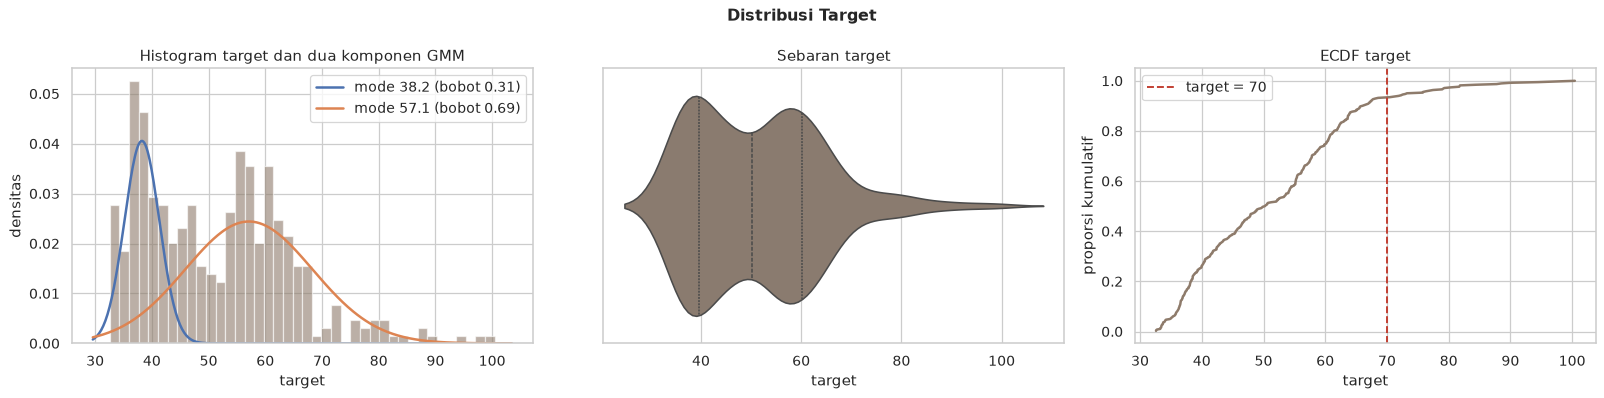

mean 51.20 | median 50.26 | std 12.89 | skew 0.75 | min 32.59 | max 100.44
baris dengan target > 70     : 26 (6.8%)
porsi squared error model fitur dari baris > 70: 40.1%
mode GMM: 38.2 (bobot 0.31), 57.1 (bobot 0.69)


In [10]:
gmm = GaussianMixture(2, random_state=CFG.SEED, n_init=10).fit(y[:, None])
order_g = np.argsort(gmm.means_.ravel())
feature_oof = CFG.FEAT_W[0] * feature_art['FM_PL_mean'] + CFG.FEAT_W[1] * feature_art['SVR_plateau_PL']
se_feature = ((feature_oof - y) ** 2).mean(0)
tail = y > 70

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
grid = np.linspace(y.min() - 3, y.max() + 3, 400)
ax[0].hist(y, bins=40, density=True, color=CFG.C_TRAIN, alpha=0.6, edgecolor='white')
for k in order_g:
    m, s, w = gmm.means_[k, 0], np.sqrt(gmm.covariances_[k].ravel()[0]), gmm.weights_[k]
    ax[0].plot(grid, w * stats.norm.pdf(grid, m, s), lw=2, label=f'mode {m:.1f} (bobot {w:.2f})')
ax[0].set(title='Histogram target dan dua komponen GMM', xlabel='target', ylabel='densitas')
ax[0].legend()
sns.violinplot(x=y, ax=ax[1], color=CFG.C_TRAIN, inner='quartile')
ax[1].set(title='Sebaran target', xlabel='target')
ax[2].plot(np.sort(y), np.arange(1, len(y) + 1) / len(y), color=CFG.C_TRAIN, lw=2)
ax[2].axvline(70, color=CFG.C_ACCENT, ls='--', label='target = 70')
ax[2].set(title='ECDF target', xlabel='target', ylabel='proporsi kumulatif')
ax[2].legend()
fig.suptitle('Distribusi Target', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '01_target_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'mean {y.mean():.2f} | median {np.median(y):.2f} | std {y.std():.2f} | skew {stats.skew(y):.2f} | '
      f'min {y.min():.2f} | max {y.max():.2f}')
print(f'baris dengan target > 70     : {tail.sum()} ({tail.mean():.1%})')
print(f'porsi squared error model fitur dari baris > 70: {se_feature[tail].sum() / se_feature.sum():.1%}')
print('mode GMM:', ', '.join(f'{gmm.means_[k, 0]:.1f} (bobot {gmm.weights_[k]:.2f})' for k in order_g))

> ### Insights
>
> Target bimodal dengan dua mode yang jelas (lihat keluaran GMM) dan batas bawah tajam di 32,6, sedangkan ekor kanannya memanjang sampai 100,4 (*skewness* 0,75). Bentuk ini tidak cocok dengan asumsi galat simetris, sehingga SVR memakai target log(y - 30) agar ekor kanan tidak mendominasi *kernel*.
>
> Hanya 26 baris (6,8%) yang bernilai di atas 70, namun baris ini menyumbang 40,1% *squared error* model fitur terbaik. Artinya, perbaikan RMSE paling besar hanya bisa datang dari baris ekor kanan, dan setiap evaluasi selanjutnya dipecah per posisi untuk melihat apakah ekor tersebut benar-benar membaik.

---

## Distribusi Fitur: *Train* vs *Test*

Jika distribusi *test* berbeda dari *train*, validasi silang acak akan menyesatkan. Setiap fitur dibandingkan dengan uji Kolmogorov-Smirnov dua sampel, dan *adversarial validation* menguji apakah sebuah *classifier* mampu membedakan baris *train* dari *test* menggunakan seluruh fitur sekaligus.

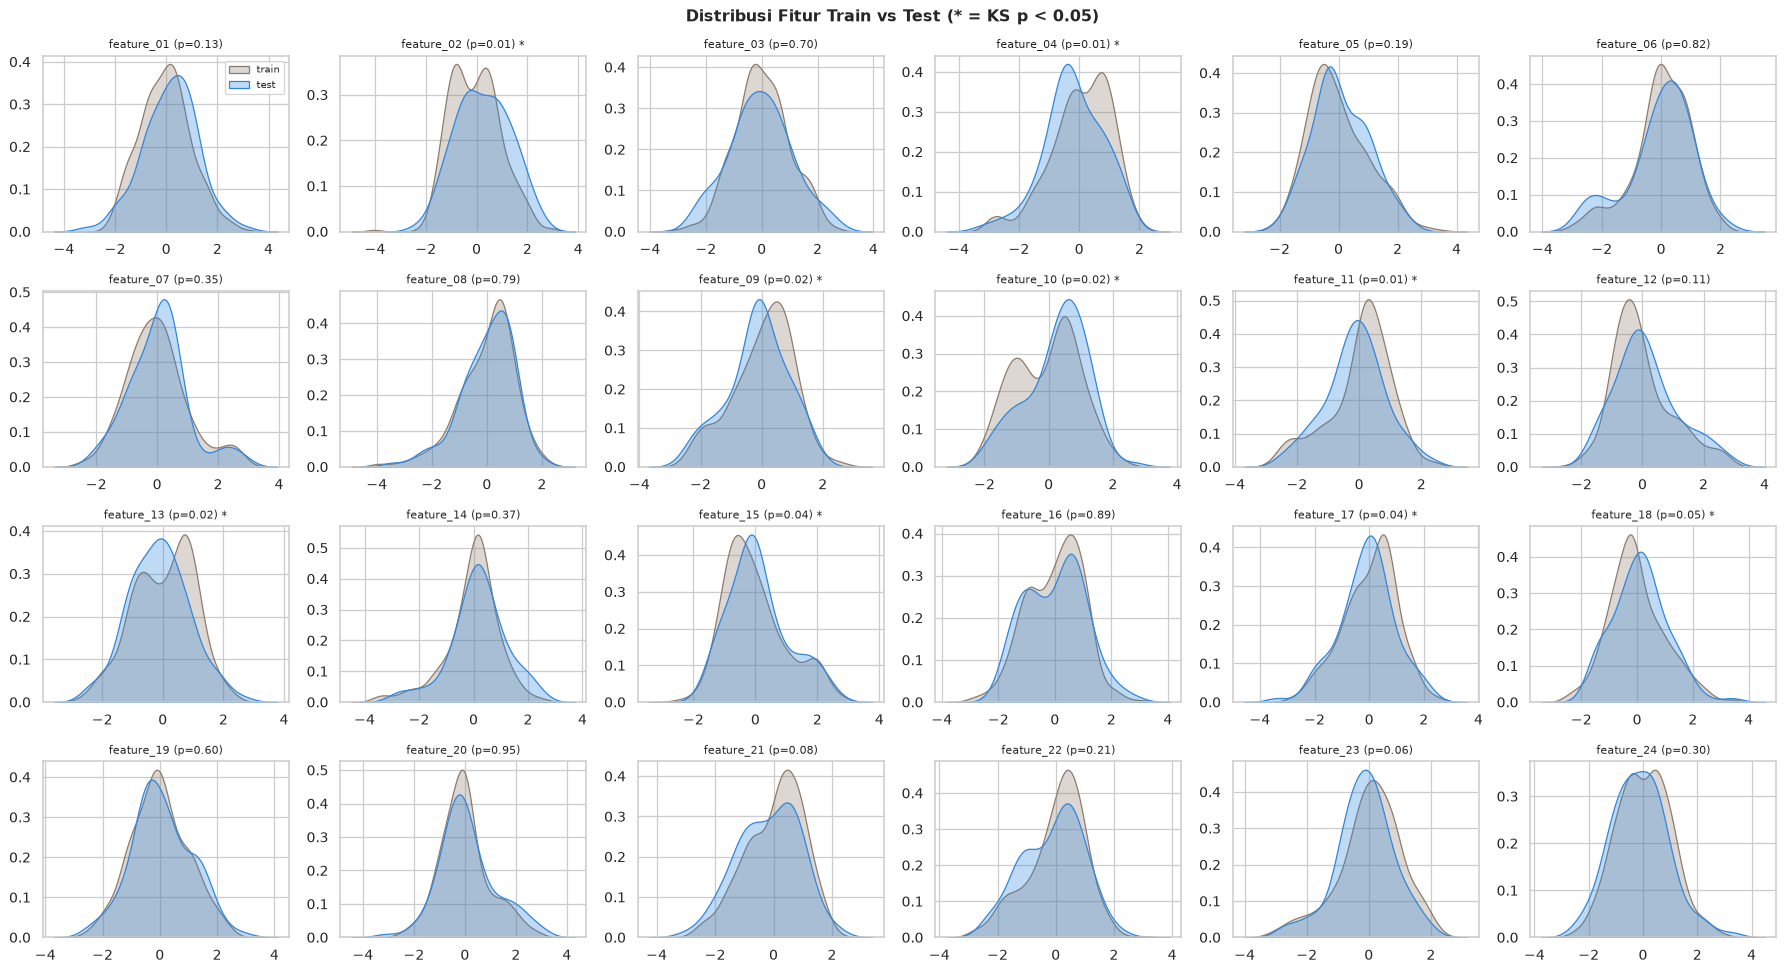

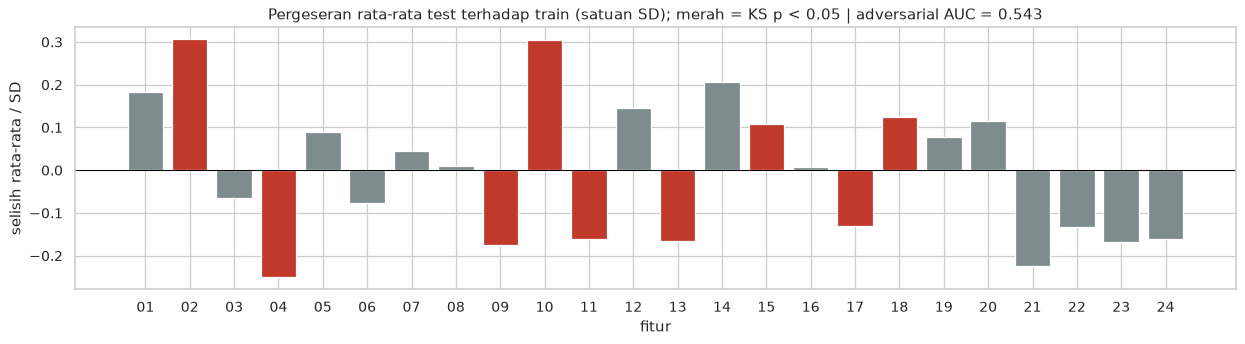

fitur dengan KS p < 0.05 : 9 dari 24
pergeseran terbesar      : 0.31 SD (feature_02)
adversarial AUC (5 seed) : 0.543 (rentang 0.525 - 0.573)


In [11]:
ks = pd.DataFrame([stats.ks_2samp(X[:, j], X_te[:, j]) for j in range(len(FEATURES))],
                  index=FEATURES)[['statistic', 'pvalue']]
ks['shift_sd'] = (X_te.mean(0) - X.mean(0)) / X_all.std(0)

fig, axes = plt.subplots(4, 6, figsize=(20, 11))
for j, ax in enumerate(axes.ravel()):
    sns.kdeplot(X[:, j], ax=ax, color=CFG.C_TRAIN, fill=True, alpha=0.3, label='train')
    sns.kdeplot(X_te[:, j], ax=ax, color=CFG.C_TEST, fill=True, alpha=0.3, label='test')
    flag = ' *' if ks['pvalue'].iloc[j] < 0.05 else ''
    ax.set_title(f'{FEATURES[j]} (p={ks["pvalue"].iloc[j]:.2f}){flag}', fontsize=9)
    ax.set(xlabel='', ylabel='')
axes[0, 0].legend(fontsize=8)
fig.suptitle('Distribusi Fitur Train vs Test (* = KS p < 0.05)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '02_feature_distributions.png', dpi=110, bbox_inches='tight')
plt.show()

is_test = np.r_[np.zeros(len(X)), np.ones(len(X_te))]
adv_auc = []
for seed in range(5):
    proba = cross_val_predict(RandomForestClassifier(300, min_samples_leaf=3, random_state=seed, n_jobs=-1),
                              X_all, is_test, cv=StratifiedKFold(5, shuffle=True, random_state=seed),
                              method='predict_proba')[:, 1]
    adv_auc.append(roc_auc_score(is_test, proba))

fig, ax = plt.subplots(figsize=(14, 4))
colors = [CFG.C_ACCENT if p < 0.05 else CFG.C_GREY for p in ks['pvalue']]
ax.bar(range(len(FEATURES)), ks['shift_sd'], color=colors)
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(range(len(FEATURES)), [f[-2:] for f in FEATURES])
ax.set(title=f'Pergeseran rata-rata test terhadap train (satuan SD); merah = KS p < 0.05 | '
             f'adversarial AUC = {np.mean(adv_auc):.3f}', xlabel='fitur', ylabel='selisih rata-rata / SD')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '03_train_test_shift.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'fitur dengan KS p < 0.05 : {(ks.pvalue < 0.05).sum()} dari {len(FEATURES)}')
print(f'pergeseran terbesar      : {ks.shift_sd.abs().max():.2f} SD ({ks.shift_sd.abs().idxmax()})')
print(f'adversarial AUC (5 seed) : {np.mean(adv_auc):.3f} (rentang {min(adv_auc):.3f} - {max(adv_auc):.3f})')

> ### Insights
>
> Sembilan dari 24 fitur lolos uji KS pada p < 0,05, tetapi pergeserannya kecil: maksimum 0,31 SD pada `feature_02`. Dengan 24 uji sekaligus, beberapa hasil signifikan memang diharapkan muncul secara kebetulan.
>
> *Adversarial validation* lebih meyakinkan: *Random Forest* hanya mencapai AUC 0,543 (rentang 0,525 sampai 0,573 untuk 5 *seed*), nyaris sama dengan tebakan acak 0,5. **Keputusan:** *train* dan *test* berasal dari distribusi fitur yang sama, sehingga *random K-fold* representatif untuk *test* dan tidak diperlukan *reweighting*.

---

## Korelasi Antarfitur dan Struktur PCA

Panitia menyebut adanya proyeksi linear privat, sehingga fitur kemungkinan merupakan kombinasi dari sedikit sinyal laten. Matriks korelasi yang diurutkan dengan *hierarchical clustering* memperlihatkan kelompok fitur, spektrum PCA dibandingkan dengan batas *noise* Marchenko-Pastur, dan RMSE regresi linear pada k komponen pertama menunjukkan di komponen mana sinyal target berada.

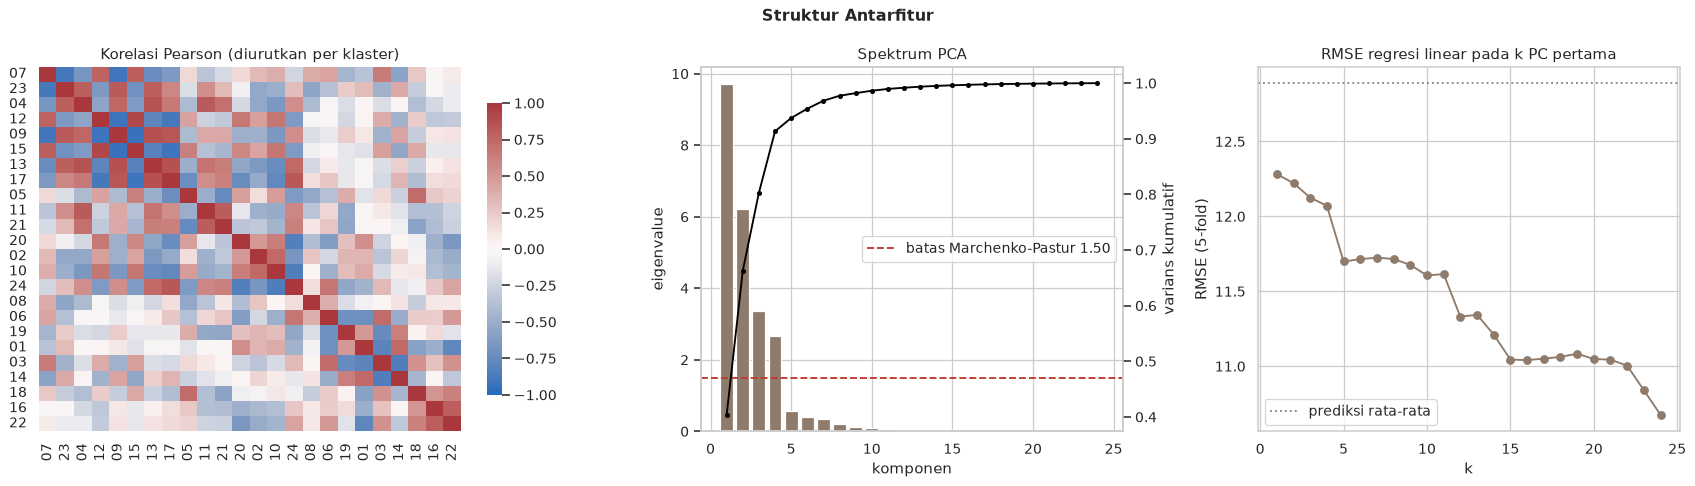

pasangan |r| > 0.7 : 43 | |r| maksimum 0.93
eigenvalue di atas batas noise : 4 | varians 4 PC pertama 91.3%
RMSE linear: 4 PC 12.07 | 12 PC 11.33 | 24 PC 10.68 | rata-rata 12.89


In [12]:
corr = train[FEATURES].corr()
leaf = leaves_list(linkage(pdist(1 - corr.abs().to_numpy()), method='average'))
corr_ord = corr.iloc[leaf, leaf]
upper = corr.abs().to_numpy()[np.triu_indices(len(FEATURES), 1)]

Z_all_std = StandardScaler().fit_transform(X_all)
pca_full = PCA().fit(Z_all_std)
eig = pca_full.explained_variance_
mp_edge = (1 + np.sqrt(len(FEATURES) / len(X_all))) ** 2

pcs_tr = pca_full.transform(Z_all_std)[:len(X)]
lin_rmse = []
for k in range(1, len(FEATURES) + 1):
    p = cross_val_predict(Ridge(alpha=1e-3), pcs_tr[:, :k], y, cv=KFold(5, shuffle=True, random_state=CFG.SEED))
    lin_rmse.append(np.sqrt(np.mean((p - y) ** 2)))

fig = plt.figure(figsize=(19, 5.5))
gs = GridSpec(1, 3, width_ratios=[1.25, 1, 1], figure=fig)
ax0, ax1, ax2 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[2])
sns.heatmap(corr_ord, cmap='vlag', center=0, vmin=-1, vmax=1, ax=ax0, cbar_kws={'shrink': 0.8},
            xticklabels=[f[-2:] for f in corr_ord.columns], yticklabels=[f[-2:] for f in corr_ord.index])
ax0.set_title('Korelasi Pearson (diurutkan per klaster)')
ax1.bar(range(1, len(eig) + 1), eig, color=CFG.C_TRAIN)
ax1.axhline(mp_edge, color=CFG.C_ACCENT, ls='--', label=f'batas Marchenko-Pastur {mp_edge:.2f}')
ax1b = ax1.twinx()
ax1b.plot(range(1, len(eig) + 1), np.cumsum(pca_full.explained_variance_ratio_), color='black', marker='o', ms=3)
ax1b.set_ylabel('varians kumulatif')
ax1b.grid(False)
ax1.set(title='Spektrum PCA', xlabel='komponen', ylabel='eigenvalue')
ax1.legend(loc='center right')
ax2.plot(range(1, len(FEATURES) + 1), lin_rmse, marker='o', color=CFG.C_TRAIN)
ax2.axhline(y.std(), color=CFG.C_GREY, ls=':', label='prediksi rata-rata')
ax2.set(title='RMSE regresi linear pada k PC pertama', xlabel='k', ylabel='RMSE (5-fold)')
ax2.legend()
fig.suptitle('Struktur Antarfitur', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '04_correlation_pca.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'pasangan |r| > 0.7 : {(upper > 0.7).sum()} | |r| maksimum {upper.max():.2f}')
print(f'eigenvalue di atas batas noise : {(eig > mp_edge).sum()} | varians 4 PC pertama {pca_full.explained_variance_ratio_[:4].sum():.1%}')
print(f'RMSE linear: 4 PC {lin_rmse[3]:.2f} | 12 PC {lin_rmse[11]:.2f} | 24 PC {lin_rmse[-1]:.2f} | rata-rata {y.std():.2f}')

> ### Insights
>
> Fitur sangat kolinear: 43 pasang memiliki |r| > 0,7 dengan maksimum 0,93, dan hanya empat *eigenvalue* yang berada di atas batas *noise* Marchenko-Pastur. Keempatnya menjelaskan 91,3% varians, sesuai dengan dugaan bahwa 24 fitur adalah proyeksi linear dari sekitar empat sinyal laten ditambah perturbasi.
>
> Namun empat komponen terbesar itu hampir tidak membawa informasi target: regresi linear pada 4 PC mencapai RMSE 12,07, hampir sama dengan memprediksi rata-rata (12,89). RMSE baru turun ke 10,68 ketika seluruh 24 PC dipakai. Sinyal target justru tersimpan di komponen bervarians kecil. **Keputusan:** tidak ada reduksi dimensi agresif; SVR memakai *view* PCA 10 sampai 20 dimensi yang di-*whitening* agar komponen kecil berbobot setara.

---

## Hubungan Fitur dengan Target

Korelasi Spearman merangkum hubungan monoton tiap fitur dengan target, sedangkan kurva LOWESS memperlihatkan bentuk hubungan yang tidak monoton. Selisih R-kuadrat LOWESS dan linear dipakai sebagai ukuran sederhana seberapa nonlinear hubungan sebuah fitur.

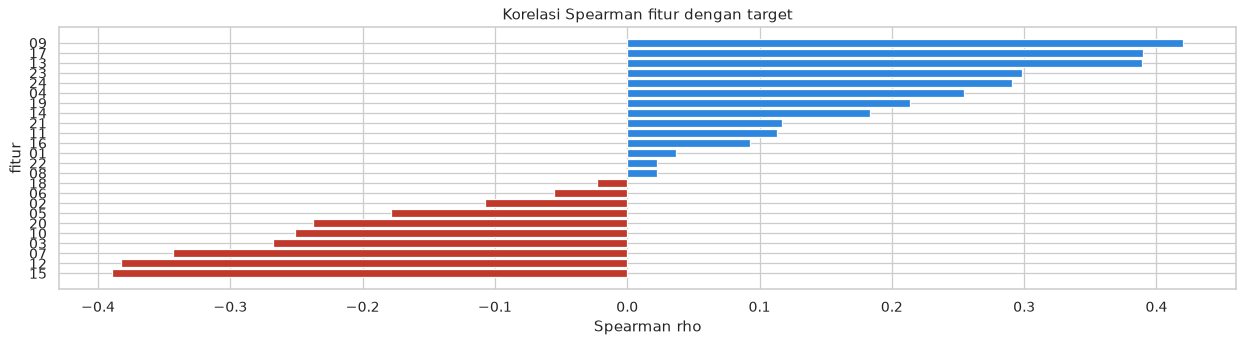

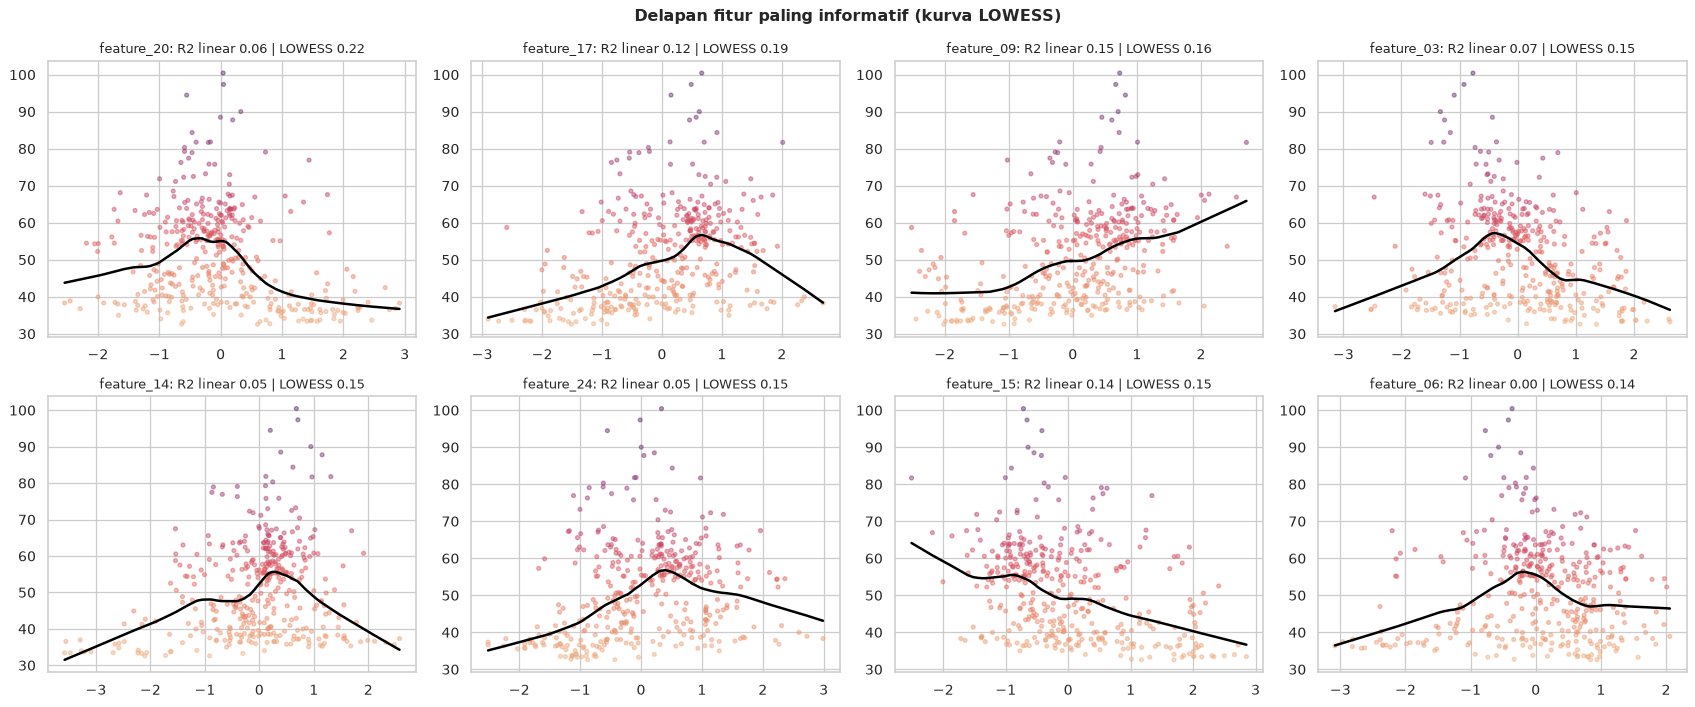

,spearman,r2_linear,r2_lowess,nonlinear_gain
feature,,,,
feature_20,-0.237,0.058,0.219,0.160
feature_17,0.390,0.124,0.191,0.068
feature_09,0.420,0.153,0.160,0.007
feature_03,-0.268,0.067,0.154,0.086
feature_14,0.183,0.046,0.153,0.107
feature_24,0.290,0.051,0.152,0.101
feature_15,-0.389,0.141,0.147,0.006
feature_06,-0.055,0.000,0.139,0.138
feature_12,-0.382,0.138,0.138,0.000


In [13]:
rel = []
for j, f in enumerate(FEATURES):
    fit = lowess(y, X[:, j], frac=0.4, return_sorted=False)
    r_lin = np.corrcoef(X[:, j], y)[0, 1] ** 2
    r_low = 1 - np.mean((y - fit) ** 2) / y.var()
    rel.append((f, stats.spearmanr(X[:, j], y).statistic, r_lin, r_low))
rel = pd.DataFrame(rel, columns=['feature', 'spearman', 'r2_linear', 'r2_lowess']).set_index('feature')
rel['nonlinear_gain'] = rel['r2_lowess'] - rel['r2_linear']

fig, ax = plt.subplots(figsize=(14, 4))
srt = rel['spearman'].sort_values()
ax.barh([f[-2:] for f in srt.index], srt, color=[CFG.C_ACCENT if v < 0 else CFG.C_TEST for v in srt])
ax.set(title='Korelasi Spearman fitur dengan target', xlabel='Spearman rho', ylabel='fitur')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '05_spearman.png', dpi=120, bbox_inches='tight')
plt.show()

top = rel['r2_lowess'].sort_values(ascending=False).index[:8]
fig, axes = plt.subplots(2, 4, figsize=(19, 8))
for ax, f in zip(axes.ravel(), top):
    j = FEATURES.index(f)
    sm = lowess(y, X[:, j], frac=0.4)
    ax.scatter(X[:, j], y, s=10, alpha=0.45, c=y, cmap='flare')
    ax.plot(sm[:, 0], sm[:, 1], color='black', lw=2)
    ax.set_title(f'{f}: R2 linear {rel.loc[f, "r2_linear"]:.2f} | LOWESS {rel.loc[f, "r2_lowess"]:.2f}', fontsize=10)
fig.suptitle('Delapan fitur paling informatif (kurva LOWESS)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '06_feature_target.png', dpi=110, bbox_inches='tight')
plt.show()

display(rel.sort_values('r2_lowess', ascending=False).head(10).round(3))

> ### Insights
>
> Tidak ada fitur yang kuat secara individual. Korelasi Spearman tertinggi hanya 0,42 (`feature_09`) dan R-kuadrat LOWESS tertinggi 0,22 (`feature_20`). Target merupakan komposit yang tersebar di banyak fitur.
>
> Beberapa fitur jelas nonlinear. `feature_20`, `feature_06`, `feature_14`, dan `feature_24` memperoleh tambahan R-kuadrat 0,10 sampai 0,16 dari kurva LOWESS dibanding garis lurus. `feature_06` bahkan tidak berkorelasi linear sama sekali (R-kuadrat 0,000) tetapi memiliki R-kuadrat LOWESS 0,14, dengan pola U terbalik. **Keputusan:** model harus nonlinear dan memakai seluruh fitur bersama-sama, yaitu *kernel* dan *foundation model*, bukan seleksi fitur.

---

## Kedekatan Antarbaris dan Duplikat Dekat

Duplikat persis tidak ditemukan, namun baris yang sangat mirip tetap dapat membuat validasi terlalu optimis apabila satu baris berada di *fold train* dan pasangannya di *fold* validasi. Jarak tetangga terdekat dihitung pada fitur terstandardisasi, lalu dibandingkan antara *train* ke *train* dan *test* ke *train*. Pasangan terdekat diperiksa apakah targetnya juga mirip.

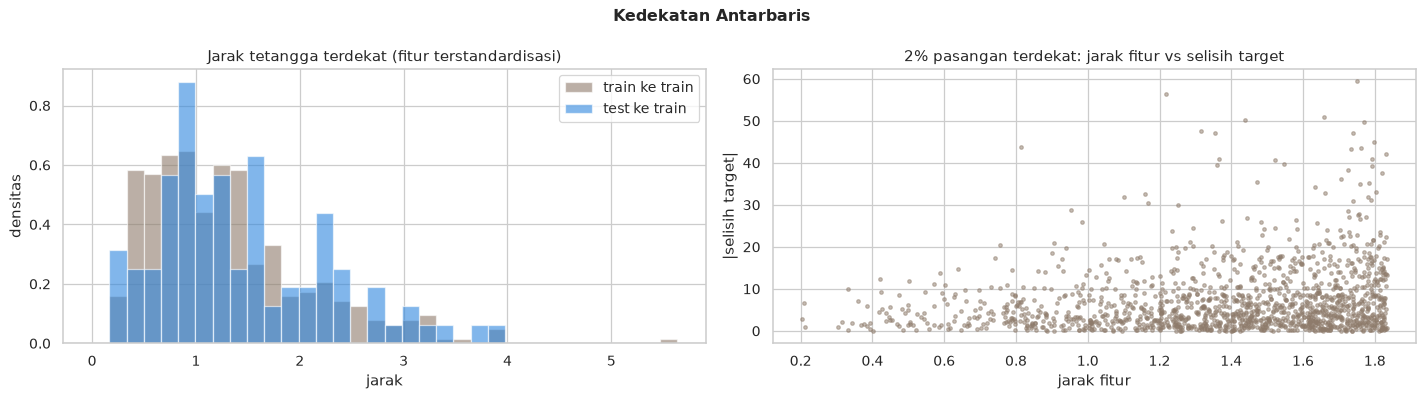

median jarak NN: train ke train 1.151 | test ke train 1.242
jarak NN minimum: train ke train 0.203 | test ke train 0.177
korelasi Spearman jarak vs selisih target (2% terdekat): 0.170


,record_a,record_b,feature_distance,abs_target_diff,row_gap
0,D0250,D0183,0.203,2.742,18
1,D0440,D0049,0.209,6.582,10
2,D0149,D0080,0.211,0.991,4
3,D0413,D0217,0.303,0.918,36
4,D0025,D0249,0.316,2.225,36
5,D0271,D0116,0.331,9.865,81
6,D0359,D0080,0.332,0.298,7
7,D0048,D0351,0.344,1.986,17


In [14]:
Z_tr, Z_te = Z_all_std[:len(X)], Z_all_std[len(X):]
D_tt = cdist(Z_tr, Z_tr)
np.fill_diagonal(D_tt, np.inf)
nn_tt, nn_et = D_tt.min(1), cdist(Z_te, Z_tr).min(1)

iu = np.triu_indices(len(X), 1)
pair_d, pair_dy = D_tt[iu], np.abs(y[iu[0]] - y[iu[1]])
closest = np.argsort(pair_d)[:8]
near_pairs = pd.DataFrame({
    'record_a': train.record_id.to_numpy()[iu[0][closest]], 'record_b': train.record_id.to_numpy()[iu[1][closest]],
    'feature_distance': pair_d[closest], 'abs_target_diff': pair_dy[closest],
    'row_gap': np.abs(iu[0][closest] - iu[1][closest]),
})

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
bins = np.linspace(0, max(nn_tt.max(), nn_et.max()), 35)
ax[0].hist(nn_tt, bins=bins, alpha=0.6, density=True, color=CFG.C_TRAIN, label='train ke train')
ax[0].hist(nn_et, bins=bins, alpha=0.6, density=True, color=CFG.C_TEST, label='test ke train')
ax[0].set(title='Jarak tetangga terdekat (fitur terstandardisasi)', xlabel='jarak', ylabel='densitas')
ax[0].legend()
close = pair_d < np.quantile(pair_d, 0.02)
ax[1].scatter(pair_d[close], pair_dy[close], s=8, alpha=0.5, color=CFG.C_TRAIN)
ax[1].set(title='2% pasangan terdekat: jarak fitur vs selisih target', xlabel='jarak fitur', ylabel='|selisih target|')
fig.suptitle('Kedekatan Antarbaris', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '07_proximity.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'median jarak NN: train ke train {np.median(nn_tt):.3f} | test ke train {np.median(nn_et):.3f}')
print(f'jarak NN minimum: train ke train {nn_tt.min():.3f} | test ke train {nn_et.min():.3f}')
print(f'korelasi Spearman jarak vs selisih target (2% terdekat): {stats.spearmanr(pair_d[close], pair_dy[close]).statistic:.3f}')
display(near_pairs.round(3))

> ### Insights
>
> Baris *test* tidak lebih dekat ke *train* dibanding baris *train* satu sama lain (median jarak tetangga terdekat 1,242 vs 1,151). Dengan demikian *random K-fold* tidak memberi keuntungan kedekatan yang tidak dimiliki *test*.
>
> Kemiripan fitur tidak menjamin kemiripan target. Pasangan terdekat D0250/D0183 (jarak 0,203) berbeda 2,74 poin, sedangkan D0271/D0116 (jarak 0,331) berbeda 9,87 poin. Korelasi antara jarak dan selisih target pada 2% pasangan terdekat hanya 0,17. **Keputusan:** baris yang mirip tidak dihapus karena tidak terbukti sebagai label salah. Uji *grouped split* saat pengembangan menunjukkan keunggulan tahap akhir tetap bertahan ketika baris yang berdekatan dipaksa berada di sisi split yang sama.

---

## Temuan Kunci: Urutan Baris Berkas

Pemeriksaan sebelumnya hanya menguji angka di dalam `record_id`, yang memang acak. Bagian ini menguji hal yang berbeda, yaitu **posisi baris di dalam berkas**. Untuk *train*, posisi langsung dibandingkan dengan target. Untuk *test*, target tidak tersedia sehingga urutannya diuji secara tidak langsung dengan dua cara: (1) apakah setiap fitur bergeser sepanjang berkas *test* dengan arah yang sama seperti pada *train*, dan (2) apakah posisi yang ditaksir dari tetangga fitur di *train* berkorelasi dengan posisi baris *test*. Penggunaan urutan ini telah dikonfirmasi panitia sebagai bagian dari EDA dan prapemrosesan peserta.

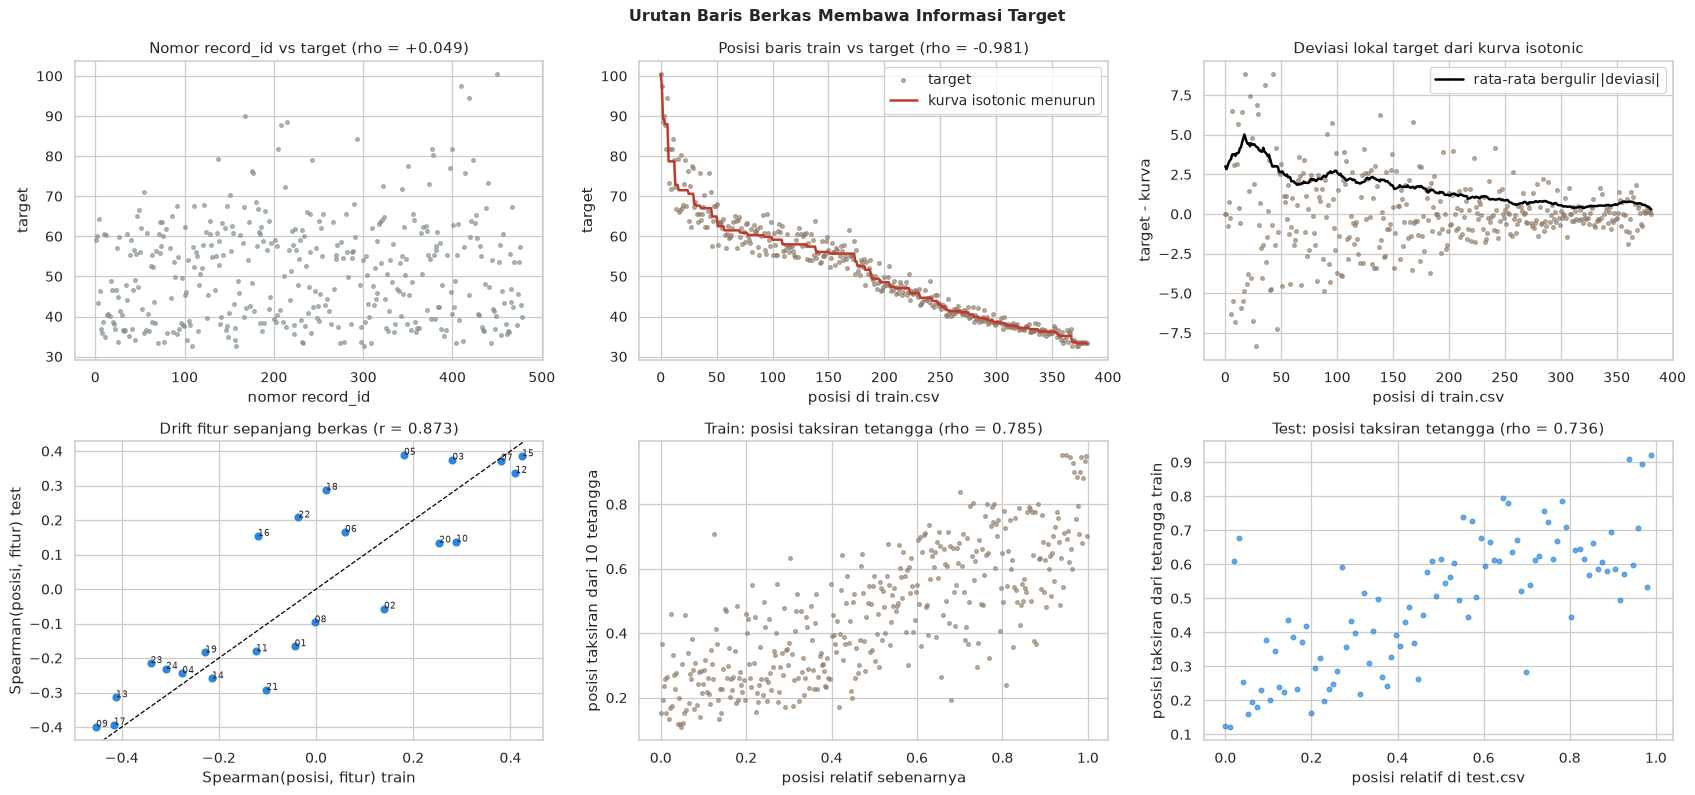

Spearman(nomor record_id, target)          : +0.049
Spearman(posisi baris train, target)        : -0.981
proporsi baris berurutan yang targetnya naik: 49.6%
RMSE kurva isotonic posisi (in-sample)      : 2.356
korelasi drift fitur train vs test          : 0.873
Spearman posisi vs taksiran tetangga, train : 0.785 | test 0.736


In [15]:
def unit_rank(n):
    return (np.arange(n) + 0.5) / n


def neighbor_signals(A, B, k=10, dim=12):
    mu, sd = A.mean(0), A.std(0)
    pc = PCA(n_components=dim, svd_solver='full').fit((A - mu) / sd)
    ZA = pc.transform((A - mu) / sd) / np.sqrt(pc.explained_variance_)
    ZB = pc.transform((B - mu) / sd) / np.sqrt(pc.explained_variance_)
    DA = cdist(ZA, ZA)
    np.fill_diagonal(DA, np.inf)
    DB = cdist(ZB, ZA)
    qa = unit_rank(len(A))

    def local(D):
        ix = np.argpartition(D, k - 1, axis=1)[:, :k]
        weights = 1 / np.maximum(np.take_along_axis(D, ix, axis=1), 0.05) ** 2
        return (weights * qa[ix]).sum(1) / weights.sum(1)

    return local(DA), local(DB)


id_num = train['record_id'].str[1:].astype(int).to_numpy()
iso_curve = IsotonicRegression(increasing=False).fit_transform(unit_rank(len(y)), y)
drift_tr = np.array([stats.spearmanr(pos_tr, X[:, j]).statistic for j in range(len(FEATURES))])
drift_te = np.array([stats.spearmanr(pos_te, X_te[:, j]).statistic for j in range(len(FEATURES))])
est_tr, est_te = neighbor_signals(X, X_te)

rho_id   = stats.spearmanr(id_num, y).statistic
rho_pos  = stats.spearmanr(pos_tr, y).statistic
rho_drift = np.corrcoef(drift_tr, drift_te)[0, 1]
rho_est_tr = stats.spearmanr(pos_tr, est_tr).statistic
rho_est_te = stats.spearmanr(pos_te, est_te).statistic

fig, ax = plt.subplots(2, 3, figsize=(19, 9))
ax[0, 0].scatter(id_num, y, s=9, alpha=0.6, color=CFG.C_GREY)
ax[0, 0].set(title=f'Nomor record_id vs target (rho = {rho_id:+.3f})', xlabel='nomor record_id', ylabel='target')
ax[0, 1].scatter(pos_tr, y, s=9, alpha=0.6, color=CFG.C_TRAIN, label='target')
ax[0, 1].plot(pos_tr, iso_curve, color=CFG.C_ACCENT, lw=2, label='kurva isotonic menurun')
ax[0, 1].set(title=f'Posisi baris train vs target (rho = {rho_pos:+.3f})', xlabel='posisi di train.csv', ylabel='target')
ax[0, 1].legend()
ax[0, 2].scatter(pos_tr, y - iso_curve, s=9, alpha=0.6, color=CFG.C_TRAIN)
ax[0, 2].plot(pos_tr, pd.Series(np.abs(y - iso_curve)).rolling(25, center=True, min_periods=5).mean(),
              color='black', lw=2, label='rata-rata bergulir |deviasi|')
ax[0, 2].set(title='Deviasi lokal target dari kurva isotonic', xlabel='posisi di train.csv', ylabel='target - kurva')
ax[0, 2].legend()
ax[1, 0].scatter(drift_tr, drift_te, s=30, color=CFG.C_TEST)
for j in range(len(FEATURES)):
    ax[1, 0].annotate(FEATURES[j][-2:], (drift_tr[j], drift_te[j]), fontsize=7)
ax[1, 0].axline((0, 0), slope=1, color='black', ls='--', lw=1)
ax[1, 0].set(title=f'Drift fitur sepanjang berkas (r = {rho_drift:.3f})', xlabel='Spearman(posisi, fitur) train',
             ylabel='Spearman(posisi, fitur) test')
ax[1, 1].scatter(pos_tr / len(y), est_tr, s=9, alpha=0.6, color=CFG.C_TRAIN)
ax[1, 1].set(title=f'Train: posisi taksiran tetangga (rho = {rho_est_tr:.3f})', xlabel='posisi relatif sebenarnya',
             ylabel='posisi taksiran dari 10 tetangga')
ax[1, 2].scatter(pos_te / len(X_te), est_te, s=14, alpha=0.7, color=CFG.C_TEST)
ax[1, 2].set(title=f'Test: posisi taksiran tetangga (rho = {rho_est_te:.3f})', xlabel='posisi relatif di test.csv',
             ylabel='posisi taksiran dari tetangga train')
fig.suptitle('Urutan Baris Berkas Membawa Informasi Target', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '08_row_order.png', dpi=120, bbox_inches='tight')
plt.show()

steps_up = np.mean(np.diff(y) > 0)
print(f'Spearman(nomor record_id, target)          : {rho_id:+.3f}')
print(f'Spearman(posisi baris train, target)        : {rho_pos:+.3f}')
print(f'proporsi baris berurutan yang targetnya naik: {steps_up:.1%}')
print(f'RMSE kurva isotonic posisi (in-sample)      : {np.sqrt(np.mean((y - iso_curve) ** 2)):.3f}')
print(f'korelasi drift fitur train vs test          : {rho_drift:.3f}')
print(f'Spearman posisi vs taksiran tetangga, train : {rho_est_tr:.3f} | test {rho_est_te:.3f}')

> ### Insights
>
> Ini temuan paling penting dari seluruh EDA. Nomor `record_id` sama sekali tidak berkorelasi dengan target (rho +0,049), tetapi **posisi baris** di `train.csv` berkorelasi -0,981. Kurva isotonic dari posisi saja mencapai RMSE *in-sample* 2,356, jauh di bawah sekitar 7,2 yang dicapai model fitur terbaik setelah delapan iterasi.
>
> Urutan tersebut hanya kasar. Pada dua baris yang berurutan, target naik di 49,6% kasus, yaitu sama seperti acak. Data tampaknya diurutkan per blok, dan di dalam blok urutannya acak. Deviasi lokal paling besar terjadi pada sekitar 50 baris pertama (rata-rata |deviasi| sekitar 4 sampai 5 poin), tepat di ekor kanan yang menyumbang 40% galat.
>
> Untuk *test*, dua bukti tidak langsung menunjuk arah yang sama: arah *drift* fitur sepanjang berkas *test* berkorelasi 0,873 dengan arah *drift* pada *train*, dan posisi yang ditaksir dari tetangga fitur berkorelasi 0,736 dengan posisi baris *test*, setara dengan 0,785 pada *train*. **Keputusan:** urutan baris menjadi lapisan kedua solusi. Peta posisi ke target (v9) menangkap tren global, taksiran tetangga mengoreksi posisi (v10), dan model residual menjelaskan deviasi lokal yang tidak dapat dijelaskan oleh urutan (v11 sampai v13).

---

## Dashboard EDA

Dashboard berikut merangkum temuan EDA dalam satu halaman: indikator kualitas data di baris atas, lalu empat grafik yang menjadi dasar keputusan pemodelan.

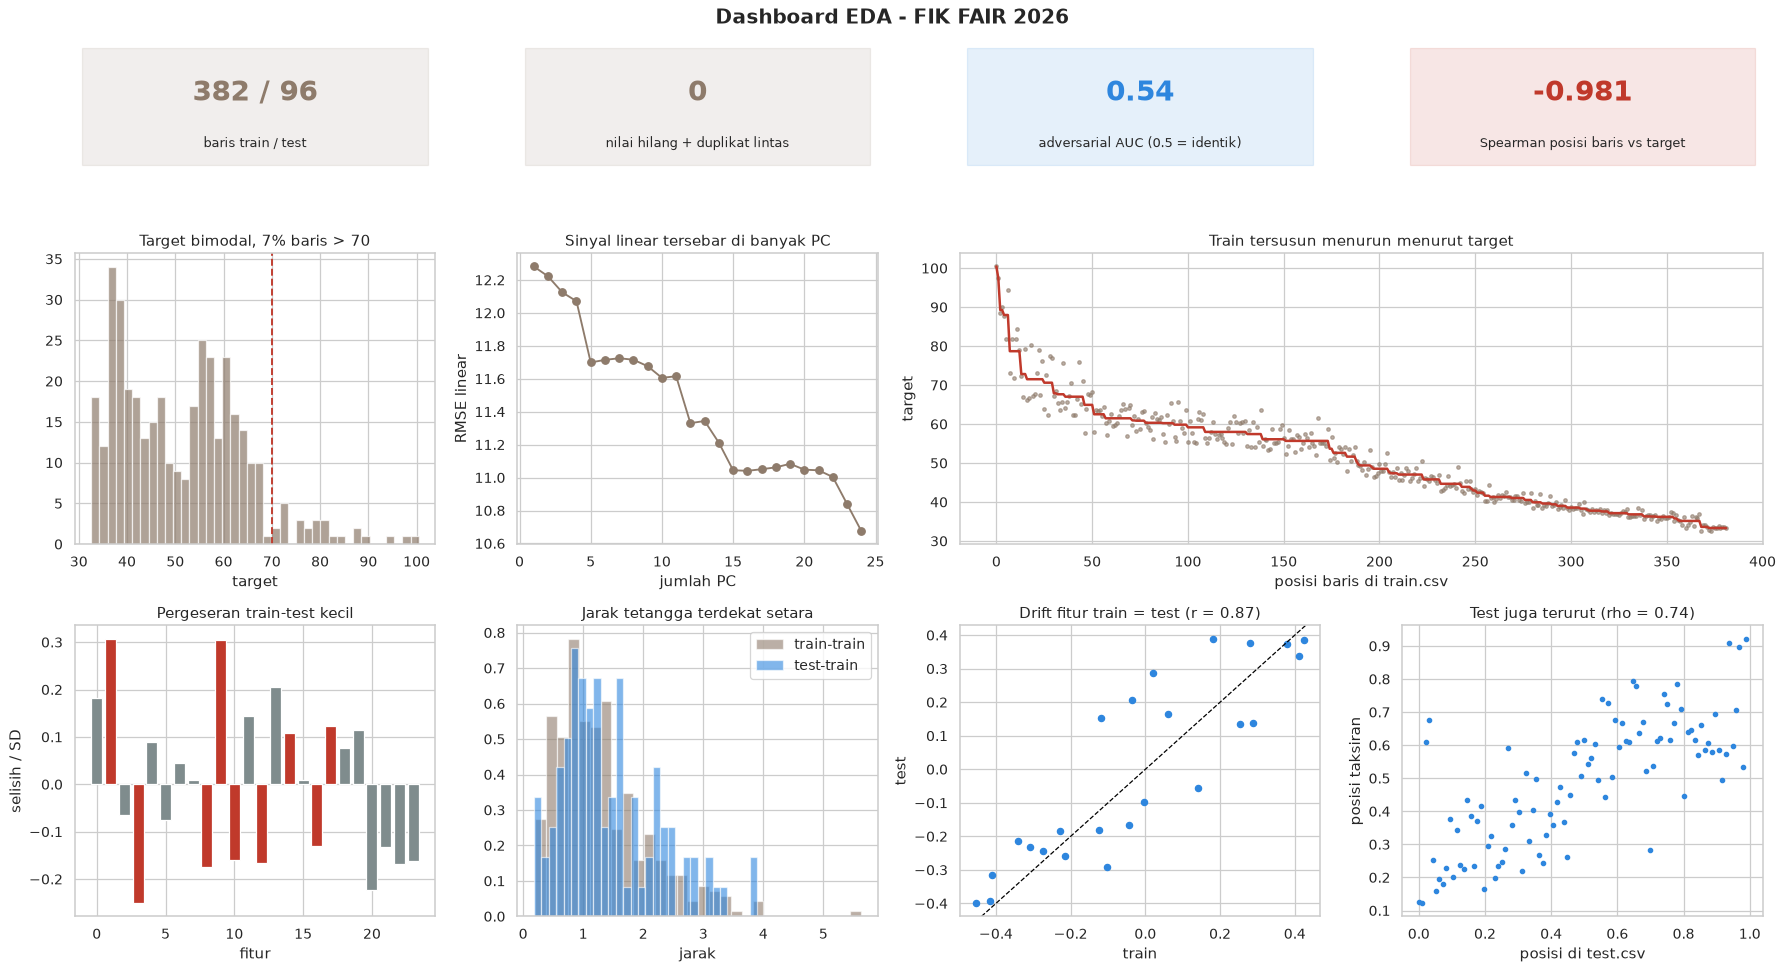

In [16]:
def kpi(ax, value, label, color=CFG.C_TRAIN):
    ax.axis('off')
    ax.add_patch(plt.Rectangle((0.02, 0.05), 0.96, 0.9, transform=ax.transAxes, color=color, alpha=0.12))
    ax.text(0.5, 0.6, value, ha='center', va='center', fontsize=22, fontweight='bold', color=color, transform=ax.transAxes)
    ax.text(0.5, 0.22, label, ha='center', va='center', fontsize=10, transform=ax.transAxes)


fig = plt.figure(figsize=(20, 11))
gs = GridSpec(3, 4, height_ratios=[0.45, 1, 1], figure=fig)
kpi(fig.add_subplot(gs[0, 0]), f'{len(train)} / {len(test)}', 'baris train / test')
kpi(fig.add_subplot(gs[0, 1]), f'{int(quality.loc["nilai hilang (fitur)", "train"]) + cross_dup}', 'nilai hilang + duplikat lintas')
kpi(fig.add_subplot(gs[0, 2]), f'{np.mean(adv_auc):.2f}', 'adversarial AUC (0.5 = identik)', CFG.C_TEST)
kpi(fig.add_subplot(gs[0, 3]), f'{rho_pos:+.3f}', 'Spearman posisi baris vs target', CFG.C_ACCENT)

a = fig.add_subplot(gs[1, 0])
a.hist(y, bins=40, color=CFG.C_TRAIN, alpha=0.7, edgecolor='white')
a.axvline(70, color=CFG.C_ACCENT, ls='--')
a.set(title=f'Target bimodal, {tail.mean():.0%} baris > 70', xlabel='target')
a = fig.add_subplot(gs[1, 1])
a.plot(range(1, len(FEATURES) + 1), lin_rmse, marker='o', color=CFG.C_TRAIN)
a.set(title='Sinyal linear tersebar di banyak PC', xlabel='jumlah PC', ylabel='RMSE linear')
a = fig.add_subplot(gs[1, 2:])
a.scatter(pos_tr, y, s=8, alpha=0.6, color=CFG.C_TRAIN)
a.plot(pos_tr, iso_curve, color=CFG.C_ACCENT, lw=2)
a.set(title='Train tersusun menurun menurut target', xlabel='posisi baris di train.csv', ylabel='target')
a = fig.add_subplot(gs[2, 0])
a.bar(range(len(FEATURES)), ks['shift_sd'], color=[CFG.C_ACCENT if p < 0.05 else CFG.C_GREY for p in ks['pvalue']])
a.set(title='Pergeseran train-test kecil', xlabel='fitur', ylabel='selisih / SD')
a = fig.add_subplot(gs[2, 1])
a.hist(nn_tt, bins=30, alpha=0.6, density=True, color=CFG.C_TRAIN, label='train-train')
a.hist(nn_et, bins=30, alpha=0.6, density=True, color=CFG.C_TEST, label='test-train')
a.set(title='Jarak tetangga terdekat setara', xlabel='jarak')
a.legend()
a = fig.add_subplot(gs[2, 2])
a.scatter(drift_tr, drift_te, s=25, color=CFG.C_TEST)
a.axline((0, 0), slope=1, color='black', ls='--', lw=1)
a.set(title=f'Drift fitur train = test (r = {rho_drift:.2f})', xlabel='train', ylabel='test')
a = fig.add_subplot(gs[2, 3])
a.scatter(pos_te / len(X_te), est_te, s=12, color=CFG.C_TEST)
a.set(title=f'Test juga terurut (rho = {rho_est_te:.2f})', xlabel='posisi di test.csv', ylabel='posisi taksiran')
fig.suptitle('Dashboard EDA - FIK FAIR 2026', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '09_eda_dashboard.png', dpi=120, bbox_inches='tight')
plt.show()

> ### Insights
>
> Cerita data dapat diringkas dalam satu kalimat: fitur bersih dan stabil antara *train* dan *test* tetapi lemah secara individual, sedangkan informasi terkuat tentang target tersimpan pada urutan baris berkas.
>
> Ketiga lapisan solusi berasal langsung dari dashboard ini. Panel distribusi dan PCA membentuk lapisan fitur yang nonlinear dan memakai seluruh komponen, panel urutan membentuk lapisan urutan, dan deviasi lokal di bagian atas berkas membentuk lapisan koreksi.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Prapemrosesan dan Rekayasa Fitur <a name="4"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Setiap langkah prapemrosesan pada bagian ini berasal dari temuan EDA dan hanya di-*fit* pada partisi *train* di dalam setiap *fold*. Informasi yang dipakai hanya fitur, target *train*, dan posisi baris. Label *test* tidak pernah tersedia maupun ditebak.

---

## Posisi Relatif dan Peta Kuantil

Berkas *train* dan *test* memiliki panjang berbeda, sehingga posisi dinormalisasi menjadi posisi relatif (i + 0,5) / n. `curve` memetakan posisi relatif ke kurva isotonic menurun dari target *train*, dengan opsi penghalusan Gaussian. `beta_curve` adalah varian yang mengintegrasikan kurva terhadap distribusi Beta dari setiap *order statistic* berkas *query*, karena baris ke-j dari 96 baris *test* tidak tepat berada di persentil j/96 data penuh.

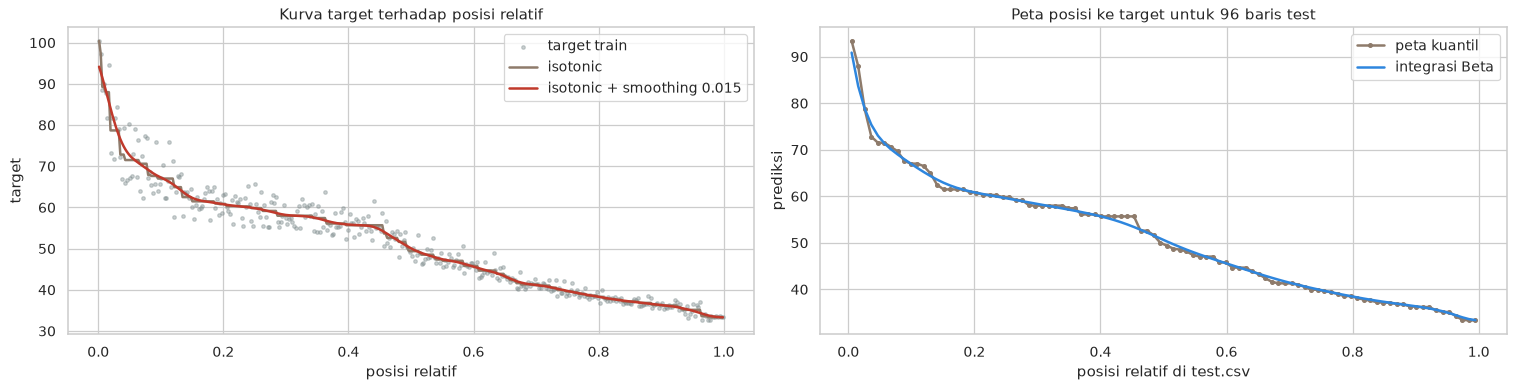

peta kuantil test: maks 93.40 | min 33.34
integrasi Beta   : maks 90.88 | min 33.39


In [17]:
def curve(t, u, smooth=0):
    q = unit_rank(len(t))
    ys = IsotonicRegression(increasing=False).fit_transform(q, t)
    if smooth:
        ys = gaussian_filter1d(ys, smooth * len(t), mode='nearest')
    return np.interp(u, q, ys)


def beta_curve(t, m):
    q = unit_rank(len(t))
    ys = IsotonicRegression(increasing=False).fit_transform(q, t)
    edges = np.r_[0, (q[1:] + q[:-1]) / 2, 1]
    j = np.arange(1, m + 1)[:, None]
    w = np.diff(betainc(j, m + 1 - j, edges[None, :]), axis=1)
    return w @ ys


u_test = unit_rank(len(X_te))
fig, ax = plt.subplots(1, 2, figsize=(17, 4.5))
ax[0].scatter(unit_rank(len(y)), y, s=8, alpha=0.4, color=CFG.C_GREY, label='target train')
ax[0].plot(unit_rank(len(y)), curve(y, unit_rank(len(y))), color=CFG.C_TRAIN, lw=2, label='isotonic')
ax[0].plot(unit_rank(len(y)), curve(y, unit_rank(len(y)), 0.015), color=CFG.C_ACCENT, lw=2, label='isotonic + smoothing 0.015')
ax[0].set(title='Kurva target terhadap posisi relatif', xlabel='posisi relatif', ylabel='target')
ax[0].legend()
ax[1].plot(u_test, curve(y, u_test), color=CFG.C_TRAIN, lw=2, marker='o', ms=3, label='peta kuantil')
ax[1].plot(u_test, beta_curve(y, len(X_te)), color=CFG.C_TEST, lw=2, label='integrasi Beta')
ax[1].set(title='Peta posisi ke target untuk 96 baris test', xlabel='posisi relatif di test.csv', ylabel='prediksi')
ax[1].legend()
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '10_quantile_map.png', dpi=120, bbox_inches='tight')
plt.show()
print(f'peta kuantil test: maks {curve(y, u_test).max():.2f} | min {curve(y, u_test).min():.2f}')
print(f'integrasi Beta   : maks {beta_curve(y, len(X_te)).max():.2f} | min {beta_curve(y, len(X_te)).min():.2f}')

> ### Insights
>
> Peta kuantil saja sudah merupakan prediktor yang sangat kuat. Untuk 96 baris *test*, prediksinya bergerak dari 93,40 di baris pertama sampai 33,34 di baris terakhir, mencakup ekor kanan yang tidak pernah dapat dijangkau model fitur. Peta ini menjadi separuh dari prediksi versi 9.
>
> Integrasi Beta lebih konservatif di ujung atas (90,88 dibanding 93,40) karena memperhitungkan bahwa posisi baris teratas *test* pada data penuh tidak pasti. Kedua varian dimasukkan ke katalog versi 10, dan *inner CV* yang menentukan mana yang lebih baik.

---

## Koreksi Posisi dari Tetangga Fitur

Posisi relatif sebuah baris di dalam berkasnya sendiri hanya taksiran posisinya pada data penuh. Fitur dapat memperbaiki taksiran ini karena baris yang fiturnya mirip cenderung berada di posisi yang mirip (EDA: rho 0,785). `neighbor_warp` (versi 10) dan `warp` (versi 11 ke atas) menaksir posisi setiap baris *query* dari 10 tetangga terdekat di ruang PCA-12 *whitened*, mengurangi bias tren yang diukur secara *leave-one-out* pada *train*, menghaluskan koreksi sepanjang berkas, mengecilkannya di kedua ujung, dan menjaga hasilnya tetap monoton. Varian `bridge` memakai *prior* Gaussian dengan kovarians *Brownian bridge*, limit dari proses rank empiris.

Grafik di bawah menguji ide ini pada satu split ilustrasi. Karena posisi sebenarnya baris validasi pada data *train* penuh diketahui, kesalahan taksiran posisi dapat diukur secara langsung.

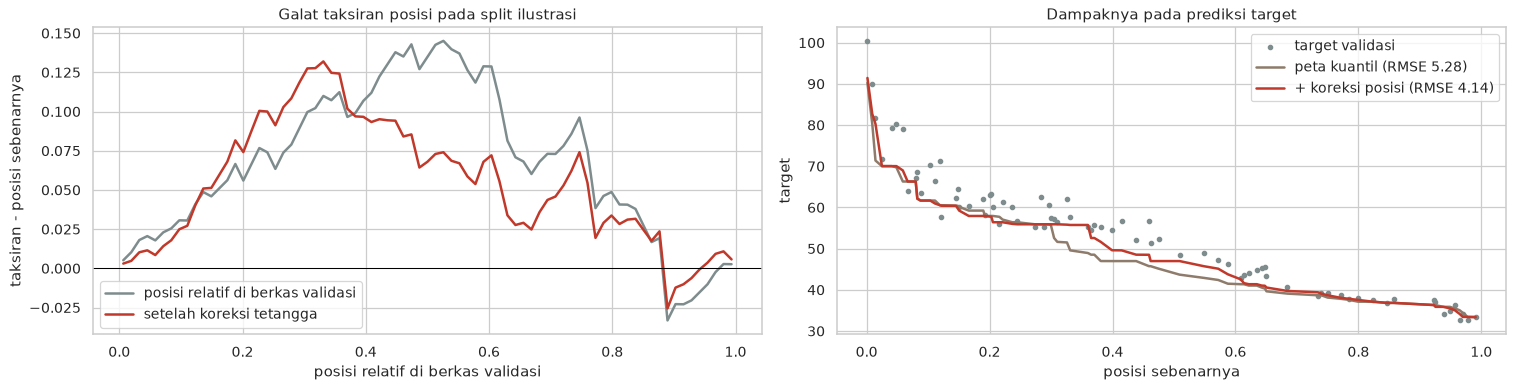

RMSE posisi: tanpa koreksi 0.0822 | dengan koreksi 0.0666
RMSE target: peta kuantil 5.278 | + koreksi posisi 4.138


In [18]:
def neighbor_warp(A, B, k=20, alpha=0.5):
    mu, sd = A.mean(0), A.std(0)
    pc = PCA(n_components=12).fit((A - mu) / sd)
    ZA = pc.transform((A - mu) / sd) / np.sqrt(pc.explained_variance_)
    ZB = pc.transform((B - mu) / sd) / np.sqrt(pc.explained_variance_)
    DAA = cdist(ZA, ZA)
    np.fill_diagonal(DAA, np.inf)
    DBA = cdist(ZB, ZA)
    qa, qb = unit_rank(len(A)), unit_rank(len(B))

    def local(D):
        idx = np.argpartition(D, k - 1, axis=1)[:, :k]
        d = np.take_along_axis(D, idx, axis=1)
        w = 1 / np.maximum(d, 0.05) ** 2
        return np.sum(w * qa[idx], axis=1) / w.sum(1)

    ref, query = local(DAA), local(DBA)
    ref_trend = gaussian_filter1d(ref, max(1, 0.05 * len(A)), mode='nearest')
    delta = query - np.interp(qb, qa, ref_trend)
    delta = gaussian_filter1d(delta, max(1, 0.10 * len(B)), mode='nearest')
    newq = np.clip(qb + alpha * 4 * qb * (1 - qb) * delta, 0, 1)
    return IsotonicRegression(increasing=True).fit_transform(qb, newq)


def warp(A, B, k=10, dim=12, kind='gaussian', strength=1.0):
    ref, query = neighbor_signals(A, B, k, dim)
    qa, qb = unit_rank(len(A)), unit_rank(len(B))
    trend = gaussian_filter1d(ref, 0.05 * len(A), mode='nearest')
    error = query - np.interp(qb, qa, trend)
    if kind == 'bridge':
        # Brownian bridge covariance: min(u, v) - u * v
        K = (np.minimum.outer(qb, qb) - np.outer(qb, qb)) * (1 / len(A) + 1 / len(B)) * strength
        derivative = np.clip(np.interp(qb, qa, np.gradient(trend, qa)), 0.1, 3.0)
        sigma2 = max(float(np.mean((ref - trend) ** 2)), 1e-4)
        cov = K * derivative[:, None] * derivative[None, :] + np.eye(len(B)) * sigma2
        correction = (K * derivative[None, :]) @ np.linalg.solve(cov, error)
    else:
        correction = strength * 4 * qb * (1 - qb) * gaussian_filter1d(error, max(1, 0.1 * len(B)), mode='nearest')
    return IsotonicRegression(increasing=True).fit_transform(qb, np.clip(qb + correction, 0, 1))


demo_tr, demo_va = map(np.sort, next(KFold(5, shuffle=True, random_state=CFG.SEED).split(X)))
u_true  = (demo_va + 0.5) / len(y)
u_naive = unit_rank(len(demo_va))
u_warp  = warp(X[demo_tr], X[demo_va])
pred_naive, pred_warp = curve(y[demo_tr], u_naive), curve(y[demo_tr], u_warp)

fig, ax = plt.subplots(1, 2, figsize=(17, 4.5))
ax[0].plot(u_naive, u_naive - u_true, color=CFG.C_GREY, lw=2, label='posisi relatif di berkas validasi')
ax[0].plot(u_naive, u_warp - u_true, color=CFG.C_ACCENT, lw=2, label='setelah koreksi tetangga')
ax[0].axhline(0, color='black', lw=0.8)
ax[0].set(title='Galat taksiran posisi pada split ilustrasi', xlabel='posisi relatif di berkas validasi',
          ylabel='taksiran - posisi sebenarnya')
ax[0].legend()
ax[1].scatter(u_true, y[demo_va], s=12, color=CFG.C_GREY, label='target validasi')
ax[1].plot(u_true, pred_naive, color=CFG.C_TRAIN, lw=2, label=f'peta kuantil (RMSE {rmse(y[demo_va], pred_naive):.2f})')
ax[1].plot(u_true, pred_warp, color=CFG.C_ACCENT, lw=2, label=f'+ koreksi posisi (RMSE {rmse(y[demo_va], pred_warp):.2f})')
ax[1].set(title='Dampaknya pada prediksi target', xlabel='posisi sebenarnya', ylabel='target')
ax[1].legend()
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '11_rank_correction.png', dpi=120, bbox_inches='tight')
plt.show()
print(f'RMSE posisi: tanpa koreksi {rmse(u_naive, u_true):.4f} | dengan koreksi {rmse(u_warp, u_true):.4f}')
print(f'RMSE target: peta kuantil {rmse(y[demo_va], pred_naive):.3f} | + koreksi posisi {rmse(y[demo_va], pred_warp):.3f}')

> ### Insights
>
> Pada split ilustrasi, posisi relatif di berkas validasi meleset secara sistematis hingga +0,14 di bagian tengah. Galatnya tidak acak per baris, melainkan berkorelasi sepanjang berkas, sesuai pola *Brownian bridge* dari proses rank empiris: nol di kedua ujung dan terbesar di tengah. Pola inilah yang dapat dikoreksi oleh tren halus.
>
> Koreksi dari tetangga fitur menurunkan RMSE posisi dari 0,0822 ke 0,0666 dan RMSE target dari 5,28 ke 4,14 pada split ini. Satu split belum cukup sebagai bukti; validasi pada 15 *fold* dengan seleksi *nested* ada di bagian Pemodelan (versi 10).

---

## *Detrending* Sepanjang Berkas

Kurva posisi menangkap tren global, sedangkan penyimpangan lokal target dari kurva tersebut (EDA: sampai sekitar 8 poin di bagian atas berkas) mungkin dijelaskan oleh fitur. Untuk memisahkan kedua komponen, tren sepanjang berkas dikurangkan dari setiap fitur dan dari target, lalu residual target dimodelkan dari residual fitur. `local_linear` adalah *smoother* lokal-linear berbobot Gaussian. Dibandingkan *filter* Gaussian biasa, *smoother* ini tidak tertarik ke tengah di ujung berkas, tempat target paling tinggi berada.

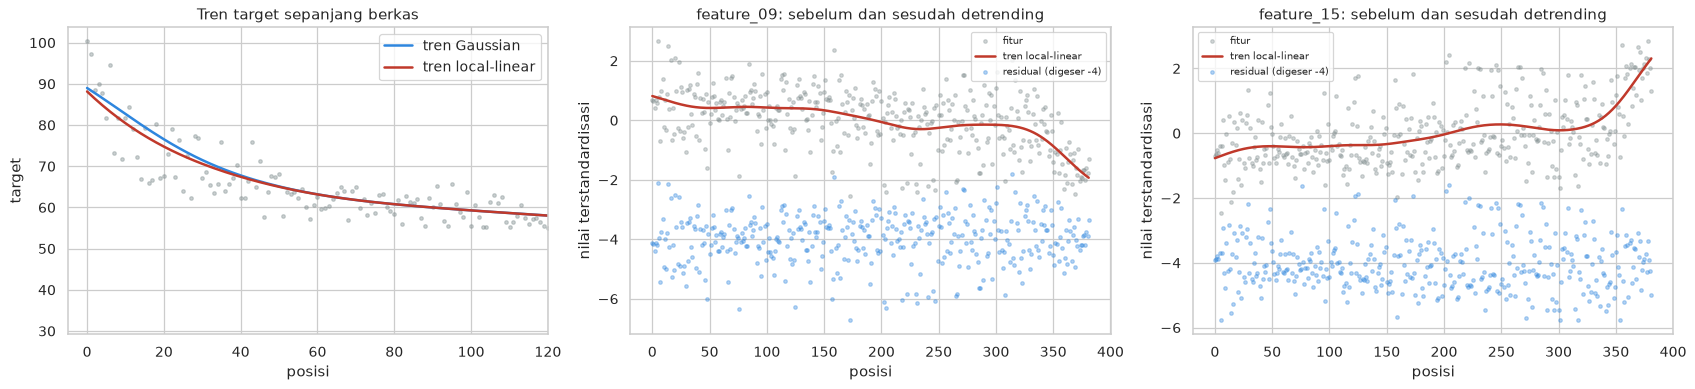

20 baris teratas: target rata-rata 80.56 | tren Gaussian 83.04 | tren local-linear 81.13
|Spearman(posisi, fitur)| rata-rata: sebelum 0.230 | sesudah detrending 0.025


In [19]:
def local_linear(z, h=0.05):
    q = unit_rank(len(z))
    dx = q[None, :] - q[:, None]
    w = np.exp(-0.5 * (dx / h) ** 2)
    s0, s1, s2 = w.sum(1), (w * dx).sum(1), (w * dx ** 2).sum(1)
    S = w * (s2[:, None] - s1[:, None] * dx) / (s0 * s2 - s1 * s1)[:, None]
    return S @ z


Zs = (X - X.mean(0)) / X.std(0)
trend_y_gauss, trend_y_ll = gaussian_filter1d(y, 0.05 * len(y), mode='nearest'), local_linear(y)
show_feat = [FEATURES.index(f) for f in ['feature_09', 'feature_15']]

fig, ax = plt.subplots(1, 3, figsize=(19, 4.5))
ax[0].scatter(pos_tr, y, s=8, alpha=0.4, color=CFG.C_GREY)
ax[0].plot(pos_tr, trend_y_gauss, color=CFG.C_TEST, lw=2, label='tren Gaussian')
ax[0].plot(pos_tr, trend_y_ll, color=CFG.C_ACCENT, lw=2, label='tren local-linear')
ax[0].set(title='Tren target sepanjang berkas', xlabel='posisi', ylabel='target', xlim=(-5, 120))
ax[0].legend()
for a, j in zip(ax[1:], show_feat):
    tr_j = local_linear(Zs[:, j])
    a.scatter(pos_tr, Zs[:, j], s=8, alpha=0.35, color=CFG.C_GREY, label='fitur')
    a.plot(pos_tr, tr_j, color=CFG.C_ACCENT, lw=2, label='tren local-linear')
    a.scatter(pos_tr, Zs[:, j] - tr_j - 4, s=8, alpha=0.35, color=CFG.C_TEST, label='residual (digeser -4)')
    a.set(title=f'{FEATURES[j]}: sebelum dan sesudah detrending', xlabel='posisi', ylabel='nilai terstandardisasi')
    a.legend(fontsize=8)
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '12_detrending.png', dpi=120, bbox_inches='tight')
plt.show()

top10 = slice(0, 20)
print(f'20 baris teratas: target rata-rata {y[top10].mean():.2f} | tren Gaussian {trend_y_gauss[top10].mean():.2f} | '
      f'tren local-linear {trend_y_ll[top10].mean():.2f}')
resid_corr = [abs(stats.spearmanr(pos_tr, Zs[:, j] - local_linear(Zs[:, j])).statistic) for j in range(len(FEATURES))]
print(f'|Spearman(posisi, fitur)| rata-rata: sebelum {np.mean(np.abs(drift_tr)):.3f} | sesudah detrending {np.mean(resid_corr):.3f}')

> ### Insights
>
> Pada 20 baris teratas (target rata-rata 80,56), tren Gaussian memberi 83,04, bias +2,5 poin karena *padding* nilai tepi, sedangkan tren *local-linear* memberi 81,13, bias +0,6 poin. Karena galat terbesar ada di ujung atas berkas, pengurangan bias di ujung ini relevan langsung terhadap RMSE.
>
> Setelah *detrending*, rata-rata |Spearman| antara posisi dan fitur turun dari 0,230 ke 0,025. Residual fitur hampir bebas dari tren urutan, sehingga model residual memakai informasi yang berbeda dari peta posisi dan keduanya saling melengkapi, bukan mengulang sinyal yang sama.

---

## Interaksi Residual dan Posisi

Efek sebuah fitur terhadap deviasi target belum tentu sama di bagian atas dan bawah berkas. Karena itu residual fitur R juga dikalikan dengan posisi tersentralisasi (2u - 1), menghasilkan matriks input [R, R x (2u - 1)] berukuran 48 kolom. Koefisien model residual dengan demikian dapat berubah secara linear sepanjang berkas. Pada versi 13, hubungan nonlinear antar-residual ditangkap oleh *Kernel Ridge* RBF dengan lebar *kernel* yang diskalakan terhadap jumlah input (gamma = g / 48).

---

## Ringkasan Keputusan Prapemrosesan

Tabel berikut merangkum langkah yang dipakai beserta bukti pendukungnya, serta ide yang diuji dan ditolak. Ide yang ditolak tetap dicantumkan agar proses seleksi transparan.

| Langkah | Dipakai pada | Bukti |
|---|---|---|
| Standardisasi + PCA *whitened* 10/12/14/16/20 dimensi | SVR | Sinyal target ada di PC kecil; rata-rata beberapa dimensi lebih stabil |
| Target log(y - 30) terstandardisasi | SVR | SVR 8,83 -> 8,35 |
| *Clipping* prediksi SVR ke rentang target *train* | SVR | Tanpa *clip* satu baris diprediksi 138 |
| `norm_methods=['none']` | TabICLv2 | 7,634 -> 7,601 |
| *Pseudo-labelling* transduktif | TabICLv2, TabPFN-3.5, SVR | TabICLv2 7,61 -> 7,52 (12 dari 15 *fold* membaik) |
| Posisi relatif + peta kuantil | Lapisan urutan | RMSE CV 7,23 -> 3,61 |
| Koreksi posisi dari tetangga PCA-12 | v10 | 3,613 -> 3,401 |
| *Detrending* + residual Ridge | v11 | 3,401 -> 3,303 |
| *Local-linear* + interaksi posisi | v12 | 3,303 -> 3,179 |
| *Kernel Ridge* RBF pada residual | v13 | 3,179 -> 3,016 |

| Ide yang ditolak | Hasil |
|---|---|
| *Quantile transform*, PCA-*denoise*, ICA | Tidak ada perbaikan; sumber ICA *heavy-tailed* |
| Target log untuk *foundation model* | Lebih buruk (7,45 -> 7,63) |
| *Fine-tuning* TabICLv2 | Lebih buruk (7,60 -> 7,69) |
| *Test-time jitter*, *subagging context* | Tidak membaik atau memburuk |
| Bobot sampel ekor, *classifier* ekor, model dua mode | Tidak membaik |
| *Clipping* fitur, *detrending* lebih lebar (v13) | Memburuk (3,517 -> 3,518; 3,544) |

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Skema Validasi <a name="5"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Dengan 382 baris dan *public leaderboard* sekitar 29 baris, keputusan model hanya dapat dipercaya bila skema validasinya meniru situasi *test* dengan setia dan tidak membocorkan label. Bagian ini mendefinisikan *fold* yang dipakai bersama oleh seluruh model dan tahap.

---

## *Repeated K-Fold* dengan Urutan Terjaga

Seluruh model memakai `RepeatedKFold` 5 *fold* x 3 *repeat* dengan *seed* 42, sehingga setiap perbandingan antarversi bersifat berpasangan. Indeks di setiap *fold* diurutkan, sehingga baris validasi membentuk berkas kecil yang **tetap tersusun dalam urutan aslinya**, persis seperti `test.csv` terhadap `train.csv`. Posisi relatif dihitung ulang di dalam setiap partisi.

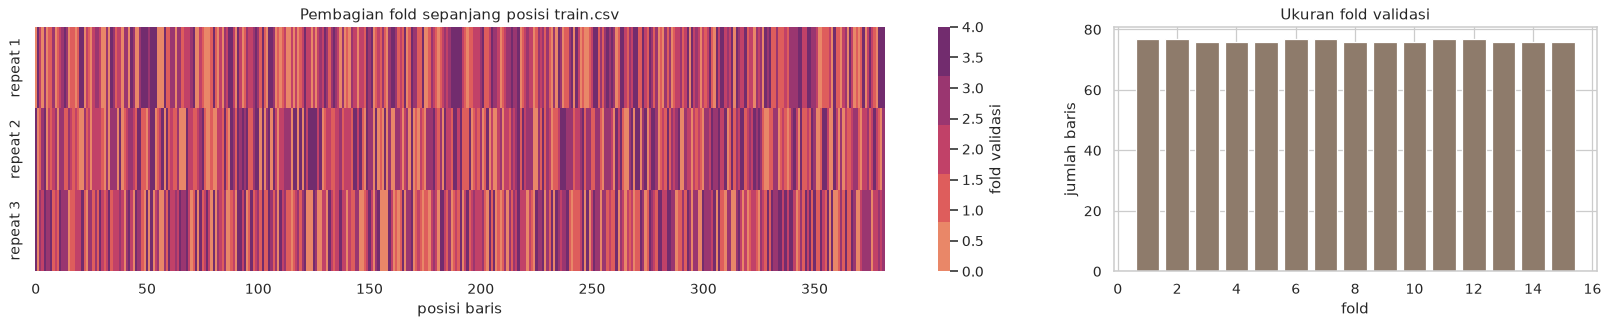

15 fold | ukuran validasi 76-77 baris | target maksimum per fold validasi 81.8-100.4


In [20]:
FOLDS = list(RepeatedKFold(n_splits=CFG.N_SPLITS, n_repeats=CFG.N_REPEATS, random_state=CFG.SEED).split(X))


def fold_rmse(p):
    return np.array([rmse(y[vai], p[i // CFG.N_SPLITS, vai]) for i, (_, vai) in enumerate(FOLDS)])


membership = np.zeros((CFG.N_REPEATS, len(y)))
for i, (_, vai) in enumerate(FOLDS):
    membership[i // CFG.N_SPLITS, vai] = i % CFG.N_SPLITS
    assert np.all(np.diff(np.sort(vai)) > 0)

fig, ax = plt.subplots(1, 2, figsize=(18, 3.8), gridspec_kw={'width_ratios': [2.2, 1]})
sns.heatmap(membership, cmap=sns.color_palette('flare', CFG.N_SPLITS), cbar_kws={'label': 'fold validasi'},
            ax=ax[0], xticklabels=50, yticklabels=[f'repeat {r + 1}' for r in range(CFG.N_REPEATS)])
ax[0].set(title='Pembagian fold sepanjang posisi train.csv', xlabel='posisi baris')
val_tops = [y[vai].max() for _, vai in FOLDS]
ax[1].bar(range(1, len(FOLDS) + 1), [len(v) for _, v in FOLDS], color=CFG.C_TRAIN)
ax[1].set(title='Ukuran fold validasi', xlabel='fold', ylabel='jumlah baris')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '13_folds.png', dpi=120, bbox_inches='tight')
plt.show()
print(f'{len(FOLDS)} fold | ukuran validasi {min(len(v) for _, v in FOLDS)}-{max(len(v) for _, v in FOLDS)} baris | '
      f'target maksimum per fold validasi {min(val_tops):.1f}-{max(val_tops):.1f}')

> ### Insights
>
> Kelima belas *fold* berukuran 76 sampai 77 baris dan tersebar merata di sepanjang berkas pada setiap *repeat*, sehingga setiap *fold* validasi menyerupai berkas *test* kecil yang terurut.
>
> Target maksimum di *fold* validasi bervariasi dari 81,8 sampai 100,4. *Fold* yang memuat baris ekor teratas akan memiliki RMSE jauh lebih tinggi, sehingga perbandingan antarversi selalu dilakukan berpasangan per *fold* dan sebarannya ikut dilaporkan, bukan hanya rata-ratanya.

---

## Seleksi *Nested* dan Bobot Tetap

Setiap tahap koreksi memiliki katalog kandidat. Pemilihan kandidat dilakukan sebagai berikut:

1. Untuk setiap *fold* luar, *inner* 5-*fold* CV **hanya pada baris *train* luar** memberi skor pada seluruh kandidat dan memilih yang terbaik (*seed inner* = offset + indeks *fold*).
2. Kandidat terpilih memprediksi baris validasi luar. Hasil ini menjadi prediksi *out-of-fold* yang jujur karena label validasi tidak pernah dilihat saat pemilihan.
3. Prediksi tahap = 0,5 x versi sebelumnya + 0,5 x kandidat terpilih. Bobot 50:50 ditetapkan sebelum evaluasi, bukan di-*fit*, karena bobot yang di-*fit* pada *fold* lain akan membawa informasi target *fold* yang sedang dievaluasi melalui peta kuantil.
4. Untuk *test*, pemilihan diulang pada seluruh 382 baris dengan *seed* final, lalu kandidat terpilih memprediksi 96 baris *test*.

Selain itu, pada saat pengembangan setiap tahap juga diuji dengan *bootstrap* berpasangan per *record*, ratusan blok *query* 96 baris yang dibagi 29/67 meniru *public*/*private*, *grouped split* untuk baris yang berdekatan, dan *learning curve*.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pemodelan <a name="6"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Pemodelan disusun mengikuti tiga lapisan pada Pendahuluan. Lapisan fitur menghasilkan prediksi dari 24 fitur, lapisan urutan menggabungkannya dengan posisi baris, dan empat tahap koreksi memperbaiki hasilnya secara bertahap. Setiap lapisan dievaluasi pada 15 *fold* yang sama.

---

## Lapisan Fitur: *Foundation Model* dan SVR dengan *Pseudo-Labelling*

Dengan 382 baris, model yang dilatih dari nol hanya memiliki sedikit data untuk mempelajari *prior*. *Tabular foundation model* adalah *transformer* yang dilatih awal pada jutaan dataset sintetis dan memprediksi baris baru lewat *in-context learning*, dengan data *train* sebagai konteks. **TabICLv2** dipakai tanpa normalisasi *power* internal dan dirata-ratakan atas 4 *seed*. **TabPFN-3.5** adalah satu-satunya checkpoint Prior Labs yang kompetitif dari versi 2.5, 2.6, 3, dan 3.5. **SVR-plateau** adalah SVR RBF pada lima *view* PCA *whitened* dengan target log(y - 30), dirata-ratakan atas empat setting C dan skala yang membentuk dataran performa.

**Pseudo-labelling transduktif.** Baris *query* (*fold* validasi, atau 96 baris *test*) diberi label awal oleh model, kemudian dibagi ke beberapa bagian. Setiap bagian diprediksi ulang dengan bagian lain yang sudah ber-*pseudo-label* ditambahkan ke konteks. Tidak ada baris yang melihat *pseudo-label*-nya sendiri, dan tidak ada label *test* yang dipakai. Cara ini memadatkan konteks di sekitar setiap *query*.

Kode di bawah dijalankan penuh pada mode `FULL` (GPU T4 x2). Pada mode `INFERENCE`, prediksi *out-of-fold* yang sama dimuat dari artefak.

In [21]:
def log_target(model):
    return TransformedTargetRegressor(model, func=lambda t: np.log(t - CFG.LOG_SHIFT),
                                      inverse_func=lambda p: np.exp(p) + CFG.LOG_SHIFT, check_inverse=False)


def z_target(model):
    return TransformedTargetRegressor(model, transformer=StandardScaler())


sc_all = StandardScaler().fit(X_all)
Z_all = sc_all.transform(X_all)


class MultiPCASVR:
    def __init__(self, cells=CFG.SVR_CELLS, clip=True):
        self.cells, self.clip = cells, clip
        self.pcas = {k: PCA(k, random_state=CFG.SEED).fit(Z_all) for k in CFG.PCA_DIMS}
        self.sds = {k: self.pcas[k].transform(Z_all).std(0) for k in CFG.PCA_DIMS}

    def _view(self, k, A):
        return self.pcas[k].transform(sc_all.transform(A)) / self.sds[k]

    def fit(self, A, t):
        self.lo, self.hi = (t.min(), t.max()) if self.clip else (-np.inf, np.inf)
        self.models = {(k, scale, C): log_target(z_target(SVR(C=C, gamma=scale / k, epsilon=0.05))).fit(self._view(k, A), t)
                       for k in CFG.PCA_DIMS for scale, C in self.cells}
        return self

    def predict(self, A):
        return np.mean([np.clip(m.predict(self._view(k, A)), self.lo, self.hi)
                        for (k, _, _), m in self.models.items()], 0)


class PseudoLabelTabICL:
    def __init__(self, device='cpu'):
        self.device = device

    def _bag(self, A, t, B):
        return np.mean([TabICLRegressor(device=self.device, random_state=s, norm_methods=CFG.ICL_NORM).fit(A, t).predict(B)
                        for s in CFG.ICL_SEEDS], 0)

    def fit(self, A, t):
        self.A, self.t = A, t
        return self

    def predict(self, B):
        first = self._bag(self.A, self.t, B)
        part = np.arange(len(B)) % CFG.PL_SPLIT
        out = np.empty(len(B))
        for k in range(CFG.PL_SPLIT):
            q, c = part == k, part != k
            out[q] = self._bag(np.vstack([self.A, B[c]]), np.r_[self.t, first[c]], B[q])
        return out


class PseudoLabelTabPFN35(PseudoLabelTabICL):
    def _bag(self, A, t, B):
        return TabPFNRegressor.create_default_for_version(
            ModelVersion.V3_5, device=self.device, n_estimators=8, random_state=CFG.SEED).fit(A, t).predict(B)


def svr_with_pseudo(A, t, B, labels_B):
    preds = []
    for n_split in CFG.SVR_PL_SPLITS:
        part = np.arange(len(B)) % n_split
        out = np.empty(len(B))
        for k in range(n_split):
            q, c = part == k, part != k
            out[q] = MultiPCASVR().fit(np.vstack([A, B[c]]), np.r_[t, labels_B[c]]).predict(B[q])
        preds.append(out)
    return np.mean(preds, 0)


def foundation_mean(A, t, B, devices):
    icl = PseudoLabelTabICL(device=devices[0]).fit(A, t).predict(B)
    pfn = PseudoLabelTabPFN35(device=devices[-1]).fit(A, t).predict(B)
    return 0.5 * (icl + pfn)

In [22]:
if CFG.RUN_MODE == 'FULL':
    start = time.time()
    devices = [f'cuda:{i}' for i in range(torch.cuda.device_count())] or ['cpu']
    fm_oof, svr_oof = np.zeros((CFG.N_REPEATS, len(y))), np.zeros((CFG.N_REPEATS, len(y)))
    for i, (tri, vai) in enumerate(FOLDS):
        r = i // CFG.N_SPLITS
        fm_oof[r, vai] = foundation_mean(X[tri], y[tri], X[vai], devices)
        svr_oof[r, vai] = svr_with_pseudo(X[tri], y[tri], X[vai], fm_oof[r, vai])
        print(f'fold {i + 1}/{len(FOLDS)} selesai ({time.time() - start:.0f} s)')
    fm_test = foundation_mean(X, y, X_te, devices)
    feat_test = CFG.FEAT_W[0] * fm_test + CFG.FEAT_W[1] * svr_with_pseudo(X, y, X_te, fm_test)
    np.savez(CFG.OUTPUT_DIR / 'feature_oof.npz', FM_PL_mean=fm_oof, SVR_plateau_PL=svr_oof)
else:
    fm_oof, svr_oof = feature_art['FM_PL_mean'], feature_art['SVR_plateau_PL']
    feat_test = None

feature_oof = CFG.FEAT_W[0] * fm_oof + CFG.FEAT_W[1] * svr_oof
layer = {'FM-PL-mean': fm_oof, 'SVR-plateau-PL': svr_oof, 'Prediksi fitur (0.7/0.3)': feature_oof}
for name, p in layer.items():
    reps = [rmse(y, pp) for pp in p]
    print(f'{name:26s} RMSE per repeat {np.round(reps, 3)} | rata-rata {np.mean(reps):.3f} | fold {fold_rmse(p).mean():.3f}')
print(f'korelasi residual FM vs SVR: {np.corrcoef((y - fm_oof).ravel(), (y - svr_oof).ravel())[0, 1]:.3f}')

FM-PL-mean                 RMSE per repeat [7.303 7.514 7.623] | rata-rata 7.480 | fold 7.444
SVR-plateau-PL             RMSE per repeat [7.703 7.892 8.109] | rata-rata 7.901 | fold 7.871
Prediksi fitur (0.7/0.3)   RMSE per repeat [7.156 7.381 7.521] | rata-rata 7.353 | fold 7.322
korelasi residual FM vs SVR: 0.850


Grafik berikut membandingkan lapisan fitur dengan model pembanding dari benchmark awal (RMSE pada prediksi *out-of-fold* yang dirata-ratakan atas 3 *repeat*), lalu memeriksa kalibrasinya per rentang target untuk melihat di mana model fitur gagal.

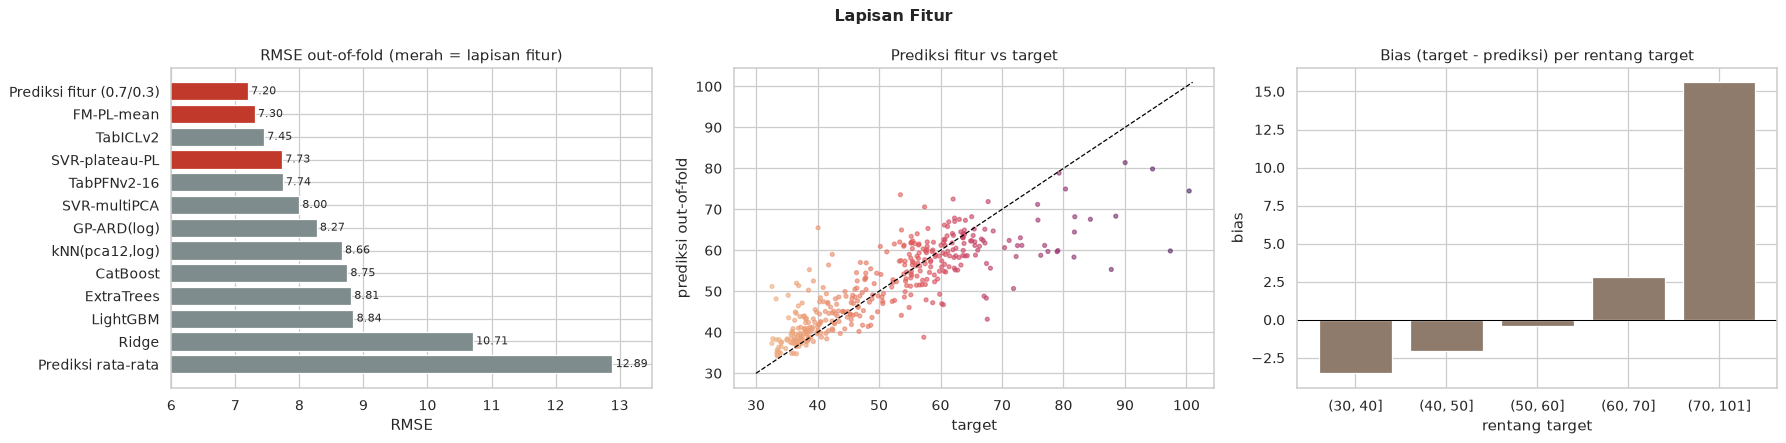

,n,target,prediksi,bias
bin,,,,
"(30, 40]",100,36.71,40.23,-3.51
"(40, 50]",90,44.55,46.62,-2.08
"(50, 60]",95,55.65,56.03,-0.38
"(60, 70]",71,63.38,60.55,2.83
"(70, 101]",26,80.49,64.89,15.60


In [23]:
pooled = {c: rmse(y, benchmark[c]) for c in benchmark.columns if c != 'record_id'}
pooled.update({name: rmse(y, p.mean(0)) for name, p in layer.items()})
pooled['Prediksi rata-rata'] = float(y.std())
pooled = pd.Series(pooled).sort_values()

bins = pd.cut(y, [30, 40, 50, 60, 70, 101])
calib = pd.DataFrame({'y': y, 'p': feature_oof.mean(0), 'bin': bins}).groupby('bin', observed=True).agg(
    n=('y', 'size'), target=('y', 'mean'), prediksi=('p', 'mean'))
calib['bias'] = calib['target'] - calib['prediksi']

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
colors = [CFG.C_ACCENT if n in layer else CFG.C_GREY for n in pooled.index]
ax[0].barh(pooled.index, pooled.values, color=colors)
ax[0].invert_yaxis()
ax[0].set(title='RMSE out-of-fold (merah = lapisan fitur)', xlabel='RMSE', xlim=(6, 13.5))
for i, v in enumerate(pooled.values):
    ax[0].text(v + 0.05, i, f'{v:.2f}', va='center', fontsize=9)
ax[1].scatter(y, feature_oof.mean(0), s=10, alpha=0.6, c=y, cmap='flare')
ax[1].plot([30, 101], [30, 101], color='black', ls='--', lw=1)
ax[1].set(title='Prediksi fitur vs target', xlabel='target', ylabel='prediksi out-of-fold')
ax[2].bar(calib.index.astype(str), calib['bias'], color=CFG.C_TRAIN)
ax[2].axhline(0, color='black', lw=0.8)
ax[2].set(title='Bias (target - prediksi) per rentang target', xlabel='rentang target', ylabel='bias')
fig.suptitle('Lapisan Fitur', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '14_feature_layer.png', dpi=120, bbox_inches='tight')
plt.show()
display(calib.round(2))

> ### Insights
>
> Lapisan fitur adalah model terbaik yang dapat dibangun dari 24 fitur saja. Rata-rata *pseudo-labelled foundation model* (RMSE 7,480 per *repeat*) mengungguli SVR (7,901), dan gabungan 0,7/0,3 turun ke 7,353 karena korelasi residual keduanya hanya 0,850. Seluruh benchmark klasik tertinggal: *gradient boosting* sekitar 8,7 sampai 8,8 dan Ridge 10,7.
>
> Grafik kalibrasi memperlihatkan batas pendekatan berbasis fitur. Prediksi menyusut ke tengah: 26 baris dengan target di atas 70 (rata-rata 80,49) hanya diprediksi 64,89, bias +15,60 poin, sedangkan baris 30 sampai 40 diprediksi 3,51 poin terlalu tinggi. Selama delapan iterasi, tidak satu pun ide berbasis fitur mampu menutup bias ekor ini. Informasi yang hilang itu justru tersedia pada urutan baris.

---

## Lapisan Urutan (Versi 9)

Untuk setiap berkas *query*, empat kandidat dibangun dari posisi relatif: peta kuantil, proyeksi isotonic dari prediksi fitur, prediksi fitur yang diurutkan ulang sesuai urutan berkas, dan prediksi fitur mentah. Tujuh aturan rata-rata ditetapkan sebelum evaluasi, tanpa bobot yang di-*fit*. Versi 9 di Kaggle memilih **rata-rata(peta kuantil, prediksi fitur terurut)**, yang dipertahankan di sini agar rantai prediksi identik dengan submisi.

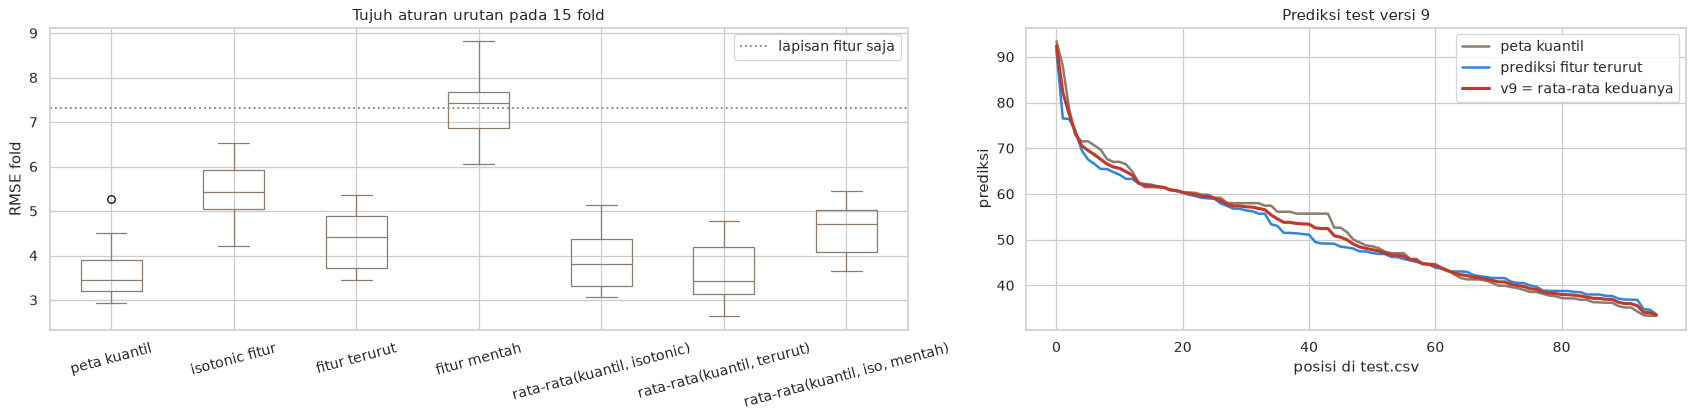

rata-rata(kuantil, terurut)        3.6132
peta kuantil                       3.6479
rata-rata(kuantil, isotonic)       3.8647
fitur terurut                      4.3590
rata-rata(kuantil, iso, mentah)    4.5627
isotonic fitur                     5.4231
fitur mentah                       7.3219

aturan terbaik: rata-rata(kuantil, terurut) | aturan v9: rata-rata(kuantil, terurut) (3.6132)
prediksi fitur terurut di test monoton: True


In [24]:
def order_candidates(y_ref, f_query):
    q = unit_rank(len(f_query))
    quantile_map = curve(y_ref, q)
    isotonic_features = IsotonicRegression(increasing=False).fit_transform(q, f_query)
    sorted_features = np.sort(f_query)[::-1]
    return np.c_[quantile_map, isotonic_features, sorted_features, f_query]


ORDER_RULES = {
    'peta kuantil'                    : [1, 0, 0, 0],
    'isotonic fitur'                  : [0, 1, 0, 0],
    'fitur terurut'                   : [0, 0, 1, 0],
    'fitur mentah'                    : [0, 0, 0, 1],
    'rata-rata(kuantil, isotonic)'    : [1 / 2, 1 / 2, 0, 0],
    'rata-rata(kuantil, terurut)'     : [1 / 2, 0, 1 / 2, 0],
    'rata-rata(kuantil, iso, mentah)' : [1 / 3, 1 / 3, 0, 1 / 3],
}
V9_RULE = 'rata-rata(kuantil, terurut)'

order_oof = {k: np.zeros((CFG.N_REPEATS, len(y))) for k in ORDER_RULES}
for i, (tri, vai) in enumerate(FOLDS):
    tri, vai = np.sort(tri), np.sort(vai)
    P = order_candidates(y[tri], feature_oof[i // CFG.N_SPLITS, vai])
    for name, w in ORDER_RULES.items():
        order_oof[name][i // CFG.N_SPLITS, vai] = P @ np.array(w, dtype=float)
rule_tab = pd.DataFrame({name: fold_rmse(p) for name, p in order_oof.items()})
v9_oof = order_oof[V9_RULE]

if CFG.RUN_MODE == 'FULL':
    v9_test = order_candidates(y, feat_test) @ np.array(ORDER_RULES[V9_RULE], dtype=float)
else:
    v9_test = test[['record_id']].merge(v9_file, on='record_id', validate='one_to_one')['prediction'].to_numpy()
feat_sorted_test = 2 * v9_test - curve(y, u_test)

fig, ax = plt.subplots(1, 2, figsize=(19, 4.8), gridspec_kw={'width_ratios': [1.3, 1]})
rule_tab.plot.box(ax=ax[0], rot=15, color=CFG.C_TRAIN)
ax[0].axhline(fold_rmse(feature_oof).mean(), color=CFG.C_GREY, ls=':', label='lapisan fitur saja')
ax[0].set(title='Tujuh aturan urutan pada 15 fold', ylabel='RMSE fold')
ax[0].legend()
ax[1].plot(pos_te, curve(y, u_test), color=CFG.C_TRAIN, lw=2, label='peta kuantil')
ax[1].plot(pos_te, feat_sorted_test, color=CFG.C_TEST, lw=2, label='prediksi fitur terurut')
ax[1].plot(pos_te, v9_test, color=CFG.C_ACCENT, lw=2.5, label='v9 = rata-rata keduanya')
ax[1].set(title='Prediksi test versi 9', xlabel='posisi di test.csv', ylabel='prediksi')
ax[1].legend()
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '15_order_layer.png', dpi=120, bbox_inches='tight')
plt.show()

print(rule_tab.mean().sort_values().round(4).to_string())
print(f'\naturan terbaik: {rule_tab.mean().idxmin()} | aturan v9: {V9_RULE} ({rule_tab[V9_RULE].mean():.4f})')
print(f'prediksi fitur terurut di test monoton: {bool(np.all(np.diff(feat_sorted_test) <= 1e-9))}')

> ### Insights
>
> Urutan baris mengubah skala masalah. Hanya dengan mengurutkan ulang prediksi fitur sesuai urutan berkas, RMSE *fold* turun dari 7,322 ke 4,359, dan peta kuantil dari posisi saja mencapai 3,648. Aturan rata-rata(kuantil, terurut) yang dipakai versi 9 juga merupakan aturan terbaik dari tujuh aturan yang ditetapkan sebelumnya (3,6132), sama persis dengan angka validasi versi 9.
>
> Prediksi fitur terurut yang direkonstruksi dari berkas versi 9 monoton sempurna, sesuai cara versi 9 dibangun. Pada grafik kanan terlihat peran kedua komponen: peta kuantil memberi rentang yang benar sampai lebih dari 90, sedangkan prediksi fitur terurut meredam lonjakan tajam di baris-baris teratas.

---

## Fungsi Tahap Koreksi dan *Runner Nested*

`predict` adalah inti versi 12 dan 13. Fungsi ini mengoreksi posisi *query* dengan `warp`, menghilangkan tren *local-linear* dari fitur dan target, membentuk residual fitur beserta interaksinya dengan posisi, lalu memprediksi residual target dengan Ridge atau *Kernel Ridge* dan menambahkannya ke kurva posisi. `gaussian_ridge` adalah versi 11 dengan tren Gaussian. Setiap tahap memiliki fungsi katalog kandidat, `select_rule` memilih kandidat dengan *inner CV*, dan `run_stage` menjalankan seleksi *nested* pada 15 *fold* serta prediksi *test*. Implementasi ini identik dengan kode pengembangan setiap versi. Pada pengembangan, setiap versi membaca versi sebelumnya dari berkas submisi CSV-nya, sehingga `as_submitted` meniru langkah tulis dan baca CSV tersebut agar hasil akhir identik per *byte*.

In [25]:
def gaussian_ridge(A, t, B, alpha):
    qa, u = unit_rank(len(A)), warp(A, B)
    mu, sd = A.mean(0), A.std(0)
    Z, Q = (A - mu) / sd, (B - mu) / sd
    tx = gaussian_filter1d(Z, 0.05 * len(A), axis=0, mode='nearest')
    ty = gaussian_filter1d(t, 0.05 * len(A), mode='nearest')
    RQ = Q - np.column_stack([np.interp(u, qa, tx[:, j]) for j in range(Z.shape[1])])
    return curve(t, u, 0.005), Ridge(alpha=alpha).fit(Z - tx, t - ty).predict(RQ)


def predict(A, t, B, config):
    qa, u = unit_rank(len(A)), warp(A, B)
    mu, sd = A.mean(0), np.maximum(A.std(0), 1e-12)
    Z, Q = (A - mu) / sd, (B - mu) / sd
    if config.get('clip'):
        lo, hi = np.quantile(Z, [0.01, 0.99], axis=0)
        Z, Q = np.clip(Z, lo, hi), np.clip(Q, lo, hi)
    target = np.log(t) if config.get('log') else t
    h = config.get('h', 0.05)
    tx, ty = local_linear(Z, h), local_linear(target, h)
    RX = Z - tx
    RQ = Q - np.column_stack([np.interp(u, qa, tx[:, j]) for j in range(Z.shape[1])])
    degree = config.get('degree', 1)
    RA = np.column_stack([RX * (2 * qa[:, None] - 1) ** d for d in range(degree + 1)])
    RB = np.column_stack([RQ * (2 * u[:, None] - 1) ** d for d in range(degree + 1)])
    resid = target - ty
    scale, query_scale = np.ones(len(t)), np.ones(len(B))
    if config.get('scaled'):
        scale = np.sqrt(np.maximum(local_linear(resid ** 2, 0.1), 1.0))
        query_scale = np.interp(u, qa, scale)
    if config.get('kernel'):
        model = KernelRidge(alpha=config.get('kernel_alpha', 1), kernel='rbf',
                            gamma=config.get('gamma_scale', 1) / RA.shape[1])
    else:
        model = Ridge(alpha=config.get('alpha', 10))
    residual = model.fit(RA, resid / scale).predict(RB) * query_scale
    if config.get('linear_curve'):
        base = np.interp(u, qa, ty)
    else:
        base = curve(target, u, config.get('smooth', 0.005))
    pred = base + residual
    if config.get('log'):
        pred = np.exp(pred)
    return pred


def stage10_candidates(A, t, B):
    out = {'quantile': curve(t, unit_rank(len(B))), 'beta': beta_curve(t, len(B))}
    for k in [10, 30]:
        for alpha in [0.6, 1.0, 1.5]:
            u = neighbor_warp(A, B, k, alpha)
            for smooth in [0, 0.005]:
                out[f'k{k}_a{alpha}_s{smooth}'] = curve(t, u, smooth)
    return out


def stage11_candidates(A, t, B):
    dims = {d: curve(t, warp(A, B, dim=d), 0.005) for d in [8, 12, 16, 20]}
    out = {'gaussian_dim8': dims[8], 'gaussian_dim12': dims[12],
           'dimension_mean': np.mean(list(dims.values()), axis=0),
           'bridge_0.5': curve(t, warp(A, B, kind='bridge', strength=0.5), 0.005)}
    rng = np.random.default_rng(5100)
    bags = []
    for _ in range(16):
        a = np.sort(rng.choice(len(A), int(0.9 * len(A)), replace=False))
        bags.append(curve(t[a], warp(A[a], B), 0.005))
    out['subbag16'] = np.mean(bags, axis=0)
    for alpha in [10, 100]:
        base, residual = gaussian_ridge(A, t, B, alpha)
        for weight in [0.5, 1.0]:
            out[f'ridge{alpha}_w{weight}'] = base + weight * residual
    return out


def stage12_candidates(A, t, B):
    base, residual = gaussian_ridge(A, t, B, 10)
    return {'gaussian_interaction0_ridge10': base + residual,
            'local_linear_interaction1_ridge10': predict(A, t, B, {})}


STAGE13_CONFIGS = {
    'baseline': {}, 'narrow': {'h': 0.025}, 'wide': {'h': 0.10},
    'ridge3': {'alpha': 3}, 'ridge30': {'alpha': 30}, 'quadratic_rank': {'degree': 2},
    'log_target': {'log': True}, 'residual_scaled': {'scaled': True},
    'kernel': {'kernel': True}, 'smooth_curve': {'smooth': 0.015},
    'linear_target_curve': {'linear_curve': True}, 'clip_features': {'clip': True},
}
STAGE13_CONFIGS.update({f'kernel_a{alpha}_g{gamma}': {'kernel': True, 'kernel_alpha': alpha, 'gamma_scale': gamma}
                        for alpha in [0.1, 0.3, 1] for gamma in [1, 2, 4] if (alpha, gamma) != (1, 1)})


def stage13_candidates(A, t, B):
    return {k: predict(A, t, B, c) for k, c in STAGE13_CONFIGS.items()}


def select_rule(candidates, A, t, seed):
    losses = {}
    for a, b in KFold(5, shuffle=True, random_state=seed).split(A):
        a, b = np.sort(a), np.sort(b)
        for key, p in candidates(A[a], t[a], A[b]).items():
            losses[key] = losses.get(key, 0.0) + np.sum((p - t[b]) ** 2)
    return min(losses, key=losses.get)


def as_submitted(pred):
    return pd.read_csv(io.StringIO(pd.DataFrame({'prediction': pred}).to_csv(index=False)))['prediction'].to_numpy()


STAGE_LOG, COMPONENT_OOF, COMPONENT_TEST, FOLD_CHOICES = [], {}, {}, {}


def run_stage(name, candidates, base_oof, base_test):
    inner_seed, final_seed, expected = CFG.STAGES[name]
    start = time.time()
    new_oof, chosen = np.zeros_like(base_oof), []
    for i, (tri, vai) in enumerate(FOLDS):
        tri, vai = np.sort(tri), np.sort(vai)
        key = select_rule(candidates, X[tri], y[tri], inner_seed + i)
        new_oof[i // CFG.N_SPLITS, vai] = candidates(X[tri], y[tri], X[vai])[key]
        chosen.append(key)
    stage_oof = 0.5 * (base_oof + new_oof)
    key = select_rule(candidates, X, y, final_seed)
    new_test = candidates(X, y, X_te)[key]
    stage_test = 0.5 * (base_test + new_test)

    base_f, comp_f, stage_f = fold_rmse(base_oof), fold_rmse(new_oof), fold_rmse(stage_oof)
    COMPONENT_OOF[name], COMPONENT_TEST[name], FOLD_CHOICES[name] = new_oof, new_test, chosen
    STAGE_LOG.append({'tahap': name, 'RMSE sebelumnya': base_f.mean(), 'RMSE komponen': comp_f.mean(),
                      'RMSE tahap': stage_f.mean(), 'fold membaik': f'{(stage_f < base_f).sum()}/{len(FOLDS)}',
                      'pilihan final': key, 'sesuai pengembangan': key == expected})
    print(f'pilihan inner per fold : {pd.Series(chosen).value_counts().to_dict()}')
    print(f'RMSE fold rata-rata    : sebelumnya {base_f.mean():.4f} | komponen {comp_f.mean():.4f} | '
          f'tahap 50:50 {stage_f.mean():.4f}')
    print(f'fold membaik           : {(stage_f < base_f).sum()}/{len(FOLDS)} | repeat membaik: '
          f'{sum(rmse(y, s) < rmse(y, b) for s, b in zip(stage_oof, base_oof))}/{CFG.N_REPEATS}')
    print(f'pilihan pada 382 baris : {key} (pengembangan: {expected}, sesuai: {key == expected})')
    print(f'perubahan prediksi test: RMS {rmse(stage_test, base_test):.4f} | waktu {time.time() - start:.0f} s')
    return stage_oof, stage_test

---

## Versi 10: Koreksi Rank dari Tetangga Fitur

Katalog versi 10 berisi peta kuantil biasa, integrasi Beta, dan koreksi tetangga dengan 10 atau 30 tetangga, tiga kekuatan koreksi (0,6; 1,0; 1,5), serta dua tingkat penghalusan kurva.

In [26]:
v10_oof, v10_test = run_stage('v10', stage10_candidates, v9_oof, v9_test)

pilihan inner per fold : {'beta': 4, 'k10_a1.5_s0.005': 4, 'k10_a1.5_s0': 2, 'k10_a1.0_s0.005': 2, 'k10_a1.0_s0': 1, 'k30_a1.5_s0.005': 1, 'k30_a1.0_s0.005': 1}
RMSE fold rata-rata    : sebelumnya 3.6132 | komponen 3.4286 | tahap 50:50 3.4008
fold membaik           : 11/15 | repeat membaik: 3/3
pilihan pada 382 baris : k10_a1.0_s0.005 (pengembangan: k10_a1.0_s0.005, sesuai: True)
perubahan prediksi test: RMS 0.7215 | waktu 3 s


> ### Insights
>
> Koreksi rank menurunkan RMSE dari 3,6132 ke 3,4008, membaik di 11 dari 15 *fold* dan di ketiga *repeat*. Interval *bootstrap* perubahan RMSE [-0,356; -0,093] seluruhnya berada di bawah nol.
>
> Pilihan *inner* berbeda antar-*fold* (integrasi Beta di 4 *fold*, koreksi 10 tetangga di 9 *fold*), yang wajar untuk data sekecil ini. Pada 382 baris, seleksi memilih `k10_a1.0_s0.005`, sama dengan pengembangan. Prediksi *test* bergeser dengan RMS 0,72 dari versi 9.

---

## Versi 11: Ridge pada Residual Fitur

Versi 11 menambahkan model residual. Tren Gaussian sepanjang berkas dikurangkan dari fitur dan target, lalu Ridge memprediksi deviasi target dari residual fitur. Katalog yang sama juga memuat alternatif stabilitas posisi: dimensi PCA berbeda, rata-ratanya, *prior Brownian bridge*, dan 16 *subsample* 90%.

In [27]:
v11_oof, v11_test = run_stage('v11', stage11_candidates, v10_oof, as_submitted(v10_test))

pilihan inner per fold : {'ridge10_w0.5': 6, 'ridge10_w1.0': 3, 'bridge_0.5': 2, 'subbag16': 2, 'gaussian_dim8': 1, 'dimension_mean': 1}
RMSE fold rata-rata    : sebelumnya 3.4008 | komponen 3.3093 | tahap 50:50 3.3031
fold membaik           : 12/15 | repeat membaik: 3/3
pilihan pada 382 baris : ridge10_w1.0 (pengembangan: ridge10_w1.0, sesuai: True)
perubahan prediksi test: RMS 0.6744 | waktu 9 s


> ### Insights
>
> Residual Ridge menurunkan RMSE dari 3,4008 ke 3,3031, membaik di 12 dari 15 *fold* dan di ketiga *repeat*, dengan interval *bootstrap* [-0,178; -0,021]. Kandidat residual Ridge alpha 10 terpilih di 9 dari 15 *fold*, sedangkan alternatif stabilitas posisi jarang menang. Artinya, gain datang dari fitur yang menjelaskan deviasi lokal, bukan dari taksiran posisi yang lebih halus.
>
> Mulai tahap ini prediksi tidak lagi dipaksa monoton sepanjang berkas, sesuai temuan EDA bahwa target hanya terurut secara kasar dan naik di separuh pasangan baris yang berurutan.

---

## Versi 12: *Local-Linear* dan Interaksi Posisi

Versi 12 membandingkan residual Gaussian versi 11 dengan residual *local-linear* yang memiliki bias lebih kecil di ujung berkas, ditambah interaksi residual x posisi. Pada pengembangan, pilihan ini diuji pada 100 split *query* 96 baris yang masing-masing dibagi 50 kali menjadi bagian 29/67 yang meniru *public* dan *private*, agar yang dinilai bukan hanya rata-rata galat tetapi juga ekor atasnya.

In [28]:
v12_oof, v12_test = run_stage('v12', stage12_candidates, v11_oof, as_submitted(v11_test))

pilihan inner per fold : {'local_linear_interaction1_ridge10': 15}
RMSE fold rata-rata    : sebelumnya 3.3031 | komponen 3.1923 | tahap 50:50 3.1789
fold membaik           : 14/15 | repeat membaik: 3/3
pilihan pada 382 baris : local_linear_interaction1_ridge10 (pengembangan: local_linear_interaction1_ridge10, sesuai: True)
perubahan prediksi test: RMS 0.5544 | waktu 1 s


> ### Insights
>
> Kandidat *local-linear* dengan interaksi posisi terpilih di **seluruh 15 *fold***. Ini sinyal paling konsisten di antara semua tahap. RMSE turun dari 3,3031 ke 3,1789, membaik di 14 dari 15 *fold*, dengan interval *bootstrap* [-0,188; -0,056].
>
> Gain ini sesuai dengan analisis *detrending*: tren *local-linear* hampir tidak bias di ujung atas berkas, tempat galat terbesar berada, dan interaksi memungkinkan efek fitur berubah sepanjang berkas.

---

## Versi 13: *Kernel Ridge* pada Residual

Dua belas ablasi satu-perubahan-per-langkah diuji pada 120 blok *query*: lebar tren, penalti Ridge, interaksi kuadratik, target log, *scaling* varians residual, *clipping* fitur, dan model residual nonlinear. Hanya *Kernel Ridge* RBF yang memberi perbaikan jelas. Studi sensitivitas 30 setting (alpha x gamma) menemukan wilayah yang baik di sekitar alpha 0,1 sampai 0,3, sehingga delapan setting di sekitarnya ditambahkan ke katalog yang berisi 20 kandidat.

In [29]:
v13_oof, v13_test = run_stage('v13', stage13_candidates, v12_oof, as_submitted(v12_test))

pilihan inner per fold : {'kernel_a0.1_g1': 4, 'kernel_a0.1_g4': 3, 'kernel_a0.3_g4': 2, 'kernel_a0.3_g1': 2, 'kernel_a0.3_g2': 1, 'kernel_a0.1_g2': 1, 'residual_scaled': 1, 'kernel': 1}
RMSE fold rata-rata    : sebelumnya 3.1789 | komponen 3.0437 | tahap 50:50 3.0156
fold membaik           : 15/15 | repeat membaik: 3/3
pilihan pada 382 baris : kernel_a0.1_g2 (pengembangan: kernel_a0.1_g2, sesuai: True)
perubahan prediksi test: RMS 0.7620 | waktu 17 s


> ### Insights
>
> *Kernel Ridge* memberi perbaikan terbesar di antara tahap koreksi: RMSE turun dari 3,1789 ke 3,0156, membaik di **15 dari 15 *fold*** dan di ketiga *repeat*, dengan interval *bootstrap* [-0,240; -0,072]. Komponen *kernel* sendiri sudah mencapai 3,0437 sebelum dirata-ratakan dengan versi 12.
>
> Varian *kernel* terpilih di 14 dari 15 *fold*. Varian yang sengaja memperburuk struktur (*clipping* fitur, tren lebih lebar) tidak pernah terpilih. Pada 382 baris, seleksi memilih alpha 0,1 dan gamma 2/48, sama dengan pengembangan, dan prediksi *test* bergeser dengan RMS 0,76 dari versi 12.

---

## Ringkasan Validasi

Tabel dan grafik berikut merangkum seluruh lapisan pada 15 *fold* yang sama: sebaran RMSE per *fold*, perubahan berpasangan setiap *fold*, dan letak galat sepanjang berkas. Interval *bootstrap* dihitung dengan me-*resample* *record* (ketiga prediksi *repeat* dari satu *record* tetap bersama) sebanyak 2.000 kali.

,RMSE sebelumnya,RMSE komponen,RMSE tahap,fold membaik,pilihan final,sesuai pengembangan
tahap,,,,,,
v10,3.6132,3.4286,3.4008,11/15,k10_a1.0_s0.005,True
v11,3.4008,3.3093,3.3031,12/15,ridge10_w1.0,True
v12,3.3031,3.1923,3.1789,14/15,local_linear_interaction1_ridge10,True
v13,3.1789,3.0437,3.0156,15/15,kernel_a0.1_g2,True


  v9 -> v10 : interval 95% perubahan RMSE [-0.356, -0.093] | membaik di 100.0% bootstrap
 v10 -> v11 : interval 95% perubahan RMSE [-0.178, -0.021] | membaik di 99.6% bootstrap
 v11 -> v12 : interval 95% perubahan RMSE [-0.188, -0.056] | membaik di 100.0% bootstrap
 v12 -> v13 : interval 95% perubahan RMSE [-0.240, -0.072] | membaik di 100.0% bootstrap


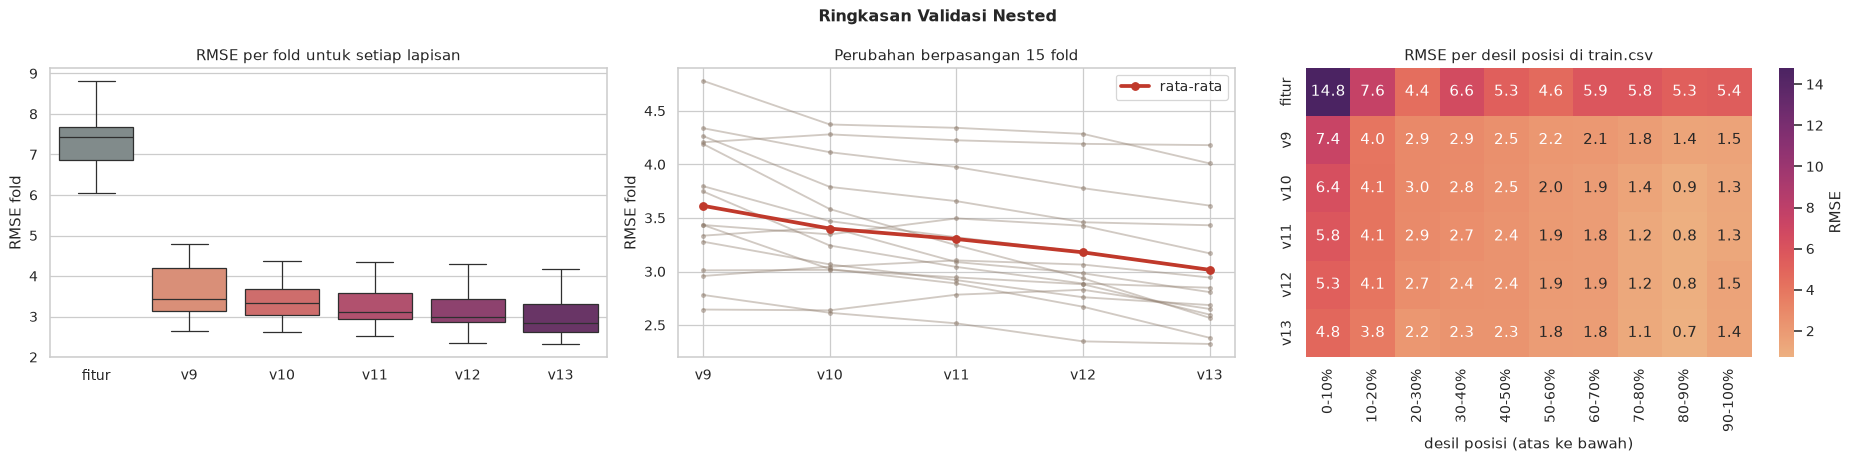

fitur    7.3219
v9       3.6132
v10      3.4008
v11      3.3031
v12      3.1789
v13      3.0156


In [30]:
VERSIONS = {'fitur': feature_oof, 'v9': v9_oof, 'v10': v10_oof, 'v11': v11_oof, 'v12': v12_oof, 'v13': v13_oof}
stage_tab = pd.DataFrame(STAGE_LOG).set_index('tahap')
display(stage_tab.round(4))

boot_rng = np.random.default_rng(CFG.SEED)
boot_idx = boot_rng.integers(0, len(y), size=(2000, len(y)))


def boot_delta(new, old):
    se_new, se_old = ((new - y) ** 2).mean(0), ((old - y) ** 2).mean(0)
    d = np.sqrt(se_new[boot_idx].mean(1)) - np.sqrt(se_old[boot_idx].mean(1))
    return np.percentile(d, [2.5, 97.5]), (d < 0).mean()


names = list(VERSIONS)
for prev, cur in zip(names[1:-1], names[2:]):
    ci, share = boot_delta(VERSIONS[cur], VERSIONS[prev])
    print(f'{prev:>4s} -> {cur:<4s}: interval 95% perubahan RMSE [{ci[0]:+.3f}, {ci[1]:+.3f}] | membaik di {share:.1%} bootstrap')

fold_tab = pd.DataFrame({k: fold_rmse(v) for k, v in VERSIONS.items()})
deciles = np.minimum((pos_tr * 10) // len(y), 9)
dec_tab = pd.DataFrame({k: [rmse(y[deciles == d], v.mean(0)[deciles == d]) for d in range(10)]
                        for k, v in VERSIONS.items()}, index=[f'{10 * d}-{10 * d + 10}%' for d in range(10)])

fig, ax = plt.subplots(1, 3, figsize=(21, 5.2))
sns.boxplot(data=fold_tab, ax=ax[0], palette=[CFG.C_GREY] + list(CFG.STAGE_COLORS.values()))
ax[0].set(title='RMSE per fold untuk setiap lapisan', ylabel='RMSE fold')
for i in range(len(FOLDS)):
    ax[1].plot(names[1:], fold_tab.iloc[i, 1:], color=CFG.C_TRAIN, alpha=0.4, marker='o', ms=3)
ax[1].plot(names[1:], fold_tab.iloc[:, 1:].mean(), color=CFG.C_ACCENT, lw=3, marker='o', label='rata-rata')
ax[1].set(title='Perubahan berpasangan 15 fold', ylabel='RMSE fold')
ax[1].legend()
sns.heatmap(dec_tab.T, annot=True, fmt='.1f', cmap='flare', ax=ax[2], cbar_kws={'label': 'RMSE'})
ax[2].set(title='RMSE per desil posisi di train.csv', xlabel='desil posisi (atas ke bawah)')
fig.suptitle('Ringkasan Validasi Nested', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '16_validation_summary.png', dpi=120, bbox_inches='tight')
plt.show()
print(fold_tab.mean().round(4).to_string())

> ### Insights
>
> Setiap tahap menurunkan RMSE rata-rata, dan interval *bootstrap* setiap transisi berada sepenuhnya di bawah nol. Dari lapisan fitur sampai versi 13, RMSE *fold* turun dari 7,32 ke 3,02. Sebaran per *fold* juga menyempit: *fold* terburuk turun dari sekitar 4,8 (v9) ke 4,2 (v13).
>
> *Heatmap* desil menunjukkan di mana perbaikan terjadi. Pada 10% baris teratas, RMSE turun dari 14,8 (fitur saja) ke 7,4 (v9) dan akhirnya 4,8 (v13), sedangkan bagian bawah berkas sudah berada di bawah 2 sejak v9. Desil teratas tetap menjadi sumber galat terbesar, sejalan dengan EDA: ekor kanan target dan deviasi lokal paling besar terletak di sana.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inferensi dan Submisi <a name="7"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Prediksi *test* sudah dihasilkan di setiap tahap oleh `run_stage`, menggunakan pilihan kandidat pada seluruh 382 baris *train*. Bagian ini menelusuri rantai prediksi tersebut, menulis berkas submisi, dan memverifikasinya terhadap berkas yang disubmit.

---

## Rantai Prediksi *Test*

Karena setiap tahap adalah rata-rata 50:50, prediksi akhir dapat diuraikan menjadi bobot tetap: 1/16 versi 9, 1/16 koreksi rank, 1/8 komponen versi 11, 1/4 komponen versi 12, dan 1/2 komponen *kernel*. Penguraian ini dihitung ulang di bawah sebagai pemeriksaan konsistensi.

selisih maksimum penguraian bobot: 1.42e-14


,record_id,posisi,v9,komponen v10,komponen v11,komponen v12,komponen v13,v13
0,D0263,0,92.369,94.214,94.409,95.533,96.884,95.788
1,D0280,1,82.253,85.851,86.560,87.049,89.260,87.719
2,D0206,2,77.549,79.020,79.059,79.642,76.615,77.886
3,D0133,3,73.350,74.402,74.056,74.664,72.526,73.421
4,D0352,4,70.529,71.701,70.474,69.652,70.931,70.577
5,D0339,5,69.517,71.430,71.818,73.065,73.919,73.012
6,D0261,6,68.597,70.649,71.725,72.806,76.727,74.234
7,D0409,7,67.573,68.611,70.169,73.043,72.981,72.034


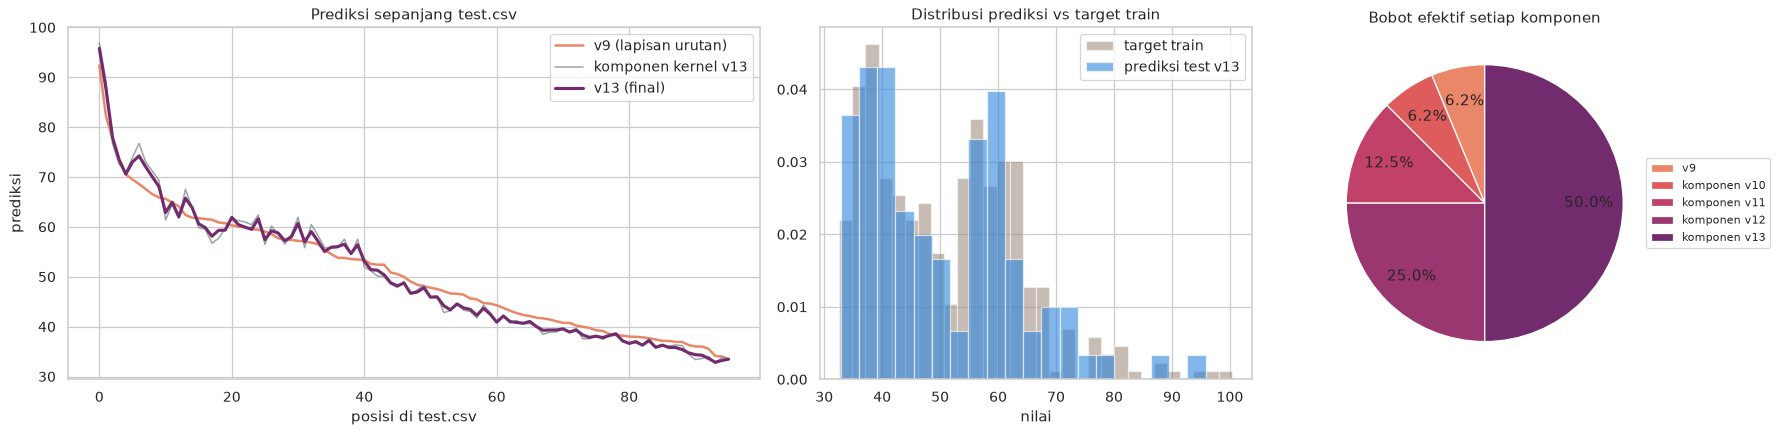

prediksi test: rata-rata 50.27 | rentang 32.86 - 95.79
target train : rata-rata 51.20 | rentang 32.59 - 100.44
Spearman(posisi test, prediksi v13): -0.994 | langkah naik antar-baris berurutan: 36.8%


In [31]:
chain = pd.DataFrame({'record_id': test['record_id'], 'posisi': pos_te, 'v9': v9_test,
                      **{f'komponen {k}': COMPONENT_TEST[k] for k in COMPONENT_TEST}, 'v13': v13_test})
weights = {'v9': 1 / 16, 'komponen v10': 1 / 16, 'komponen v11': 1 / 8, 'komponen v12': 1 / 4, 'komponen v13': 1 / 2}
recomposed = sum(w * chain[c] for c, w in weights.items())
print(f'selisih maksimum penguraian bobot: {np.abs(recomposed - v13_test).max():.2e}')
display(chain.head(8).round(3))

fig = plt.figure(figsize=(20, 5))
gs = GridSpec(1, 3, width_ratios=[1.6, 1, 0.8], figure=fig)
a = fig.add_subplot(gs[0])
a.plot(pos_te, v9_test, color=CFG.STAGE_COLORS['v9'], lw=2, label='v9 (lapisan urutan)')
a.plot(pos_te, COMPONENT_TEST['v13'], color=CFG.C_GREY, lw=1.2, alpha=0.8, label='komponen kernel v13')
a.plot(pos_te, v13_test, color=CFG.STAGE_COLORS['v13'], lw=2.5, label='v13 (final)')
a.set(title='Prediksi sepanjang test.csv', xlabel='posisi di test.csv', ylabel='prediksi')
a.legend()
a = fig.add_subplot(gs[1])
a.hist(y, bins=30, density=True, alpha=0.5, color=CFG.C_TRAIN, label='target train')
a.hist(v13_test, bins=20, density=True, alpha=0.6, color=CFG.C_TEST, label='prediksi test v13')
a.set(title='Distribusi prediksi vs target train', xlabel='nilai')
a.legend()
a = fig.add_subplot(gs[2])
a.pie(list(weights.values()), autopct='%1.1f%%', pctdistance=0.75, colors=list(CFG.STAGE_COLORS.values()),
      startangle=90, wedgeprops={'edgecolor': 'white'})
a.legend(list(weights), loc='center left', bbox_to_anchor=(0.95, 0.5), fontsize=9)
a.set_title('Bobot efektif setiap komponen')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '17_test_chain.png', dpi=120, bbox_inches='tight')
plt.show()
print(f'prediksi test: rata-rata {v13_test.mean():.2f} | rentang {v13_test.min():.2f} - {v13_test.max():.2f}')
print(f'target train : rata-rata {y.mean():.2f} | rentang {y.min():.2f} - {y.max():.2f}')
print(f'Spearman(posisi test, prediksi v13): {stats.spearmanr(pos_te, v13_test).statistic:.3f} | '
      f'langkah naik antar-baris berurutan: {np.mean(np.diff(v13_test) > 0):.1%}')

> ### Insights
>
> Penguraian bobot mereproduksi prediksi akhir sampai galat pembulatan (sekitar 1e-14, berasal dari langkah baca-tulis CSV antarversi). Prediksi akhir benar-benar merupakan kombinasi tetap dari lima komponen, tanpa bobot tersembunyi.
>
> Prediksi *test* (rata-rata 50,27, rentang 32,86 sampai 95,79) menutupi hampir seluruh rentang target *train* (32,59 sampai 100,44), berbeda dengan model fitur yang menyusut ke tengah. Prediksi mengikuti urutan berkas (Spearman -0,994), tetapi naik di 36,8% pasangan baris berurutan. Koreksi residual mempertahankan variasi lokal yang dalam EDA terbukti ada pada target, alih-alih memaksa kurva monoton.
>
> Pada baris-baris teratas, komponen *kernel* berani menyimpang dari versi 9 (misalnya D0261: 68,60 menjadi 76,73), sedangkan bobot 50:50 meredam setiap penyimpangan menjadi separuhnya. Ini adalah bentuk *shrinkage* yang disengaja terhadap komponen paling fleksibel.

---

## Pembuatan Berkas Submisi

Berkas submisi mengikuti urutan dan kolom `submission_template.csv`, dengan tepat satu prediksi untuk setiap `record_id`. Seluruh syarat format diperiksa dengan *assertion* sebelum berkas ditulis, dan *hash* SHA256 dicetak sebagai identitas berkas.

In [32]:
submission = template[['record_id']].merge(
    pd.DataFrame({'record_id': test['record_id'], 'prediction': v13_test}),
    on='record_id', how='left', validate='one_to_one')

assert list(submission.columns) == ['record_id', 'prediction']
assert len(submission) == len(template) == len(test)
assert submission['record_id'].is_unique and set(submission['record_id']) == set(test['record_id'])
assert np.isfinite(submission['prediction']).all()

csv_text = submission.to_csv(index=False)
CFG.SUBMISSION_CSV.write_text(csv_text)
submission_sha = hashlib.sha256(CFG.SUBMISSION_CSV.read_bytes()).hexdigest()
print(f'berkas : {CFG.SUBMISSION_CSV}')
print(f'SHA256 : {submission_sha}')
display(submission.head())

berkas : ../outputs/fikfair_final/submission.csv
SHA256 : 0bd8ba26554f5163d14bfedbc70b9a134cfa458505e268c6ffb105e6cd07af14


,record_id,prediction
0,D0263,95.787544
1,D0280,87.718539
2,D0206,77.886174
3,D0133,73.420571
4,D0352,70.577032


---

## Verifikasi terhadap Submisi

Berkas yang baru ditulis dibandingkan dengan `submission_v13.csv` yang disubmit ke Kaggle, baik per *byte* maupun per nilai. Pada mode `INFERENCE`, notebook berhenti dengan *error* bila selisihnya melebihi 1e-6, sehingga reproduksi tidak dapat lolos secara diam-diam. Versi pustaka yang berbeda dapat menggeser digit terakhir representasi desimal, sehingga kesamaan per *byte* hanya dijamin pada lingkungan yang sama.

In [33]:
reference_path = CFG.ARTIFACT_DIR / 'submission_v13.csv'
reference = pd.read_csv(reference_path, float_precision='round_trip')
ref_pred = submission[['record_id']].merge(reference, on='record_id', validate='one_to_one')['prediction'].to_numpy()
max_diff = float(np.abs(submission['prediction'].to_numpy() - ref_pred).max())
byte_identical = CFG.SUBMISSION_CSV.read_bytes() == reference_path.read_bytes()

print(f'SHA256 referensi       : {hashlib.sha256(reference_path.read_bytes()).hexdigest()}')
print(f'identik per byte       : {byte_identical}')
print(f'selisih nilai maksimum : {max_diff:.2e}')
if CFG.RUN_MODE == 'INFERENCE':
    assert max_diff < 1e-6, 'submisi tidak mereproduksi submission_v13.csv'
    print('Reproduksi submission_v13.csv: BERHASIL')

SHA256 referensi       : 0bd8ba26554f5163d14bfedbc70b9a134cfa458505e268c6ffb105e6cd07af14
identik per byte       : True
selisih nilai maksimum : 0.00e+00
Reproduksi submission_v13.csv: BERHASIL


> ### Insights
>
> Berkas yang dihasilkan notebook identik per *byte* dengan `submission_v13.csv` yang disubmit: SHA256 keduanya `0bd8ba26...af14` dan selisih nilainya tepat nol. Seluruh rantai dari artefak lapisan fitur sampai submisi dapat direproduksi tanpa GPU dan tanpa token.
>
> Pada mode `FULL`, lapisan fitur dihitung ulang di GPU dan dapat berbeda sangat sedikit antar-*run*. Lapisan fitur hanya masuk ke prediksi akhir melalui versi 9 dengan bobot 1/16, sehingga perbedaan tersebut teredam enam belas kali.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Dashboard Solusi <a name="8"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Dashboard berikut merangkum seluruh solusi dalam satu halaman: indikator utama di baris atas, perjalanan skor CV dan *public* dari v1 sampai v13, sebaran galat per *fold*, kalibrasi per rentang target, galat per desil posisi, dan prediksi akhir sepanjang berkas *test*. Skor *public* adalah skor yang tercatat saat submisi dan tidak dipakai dalam pemodelan.

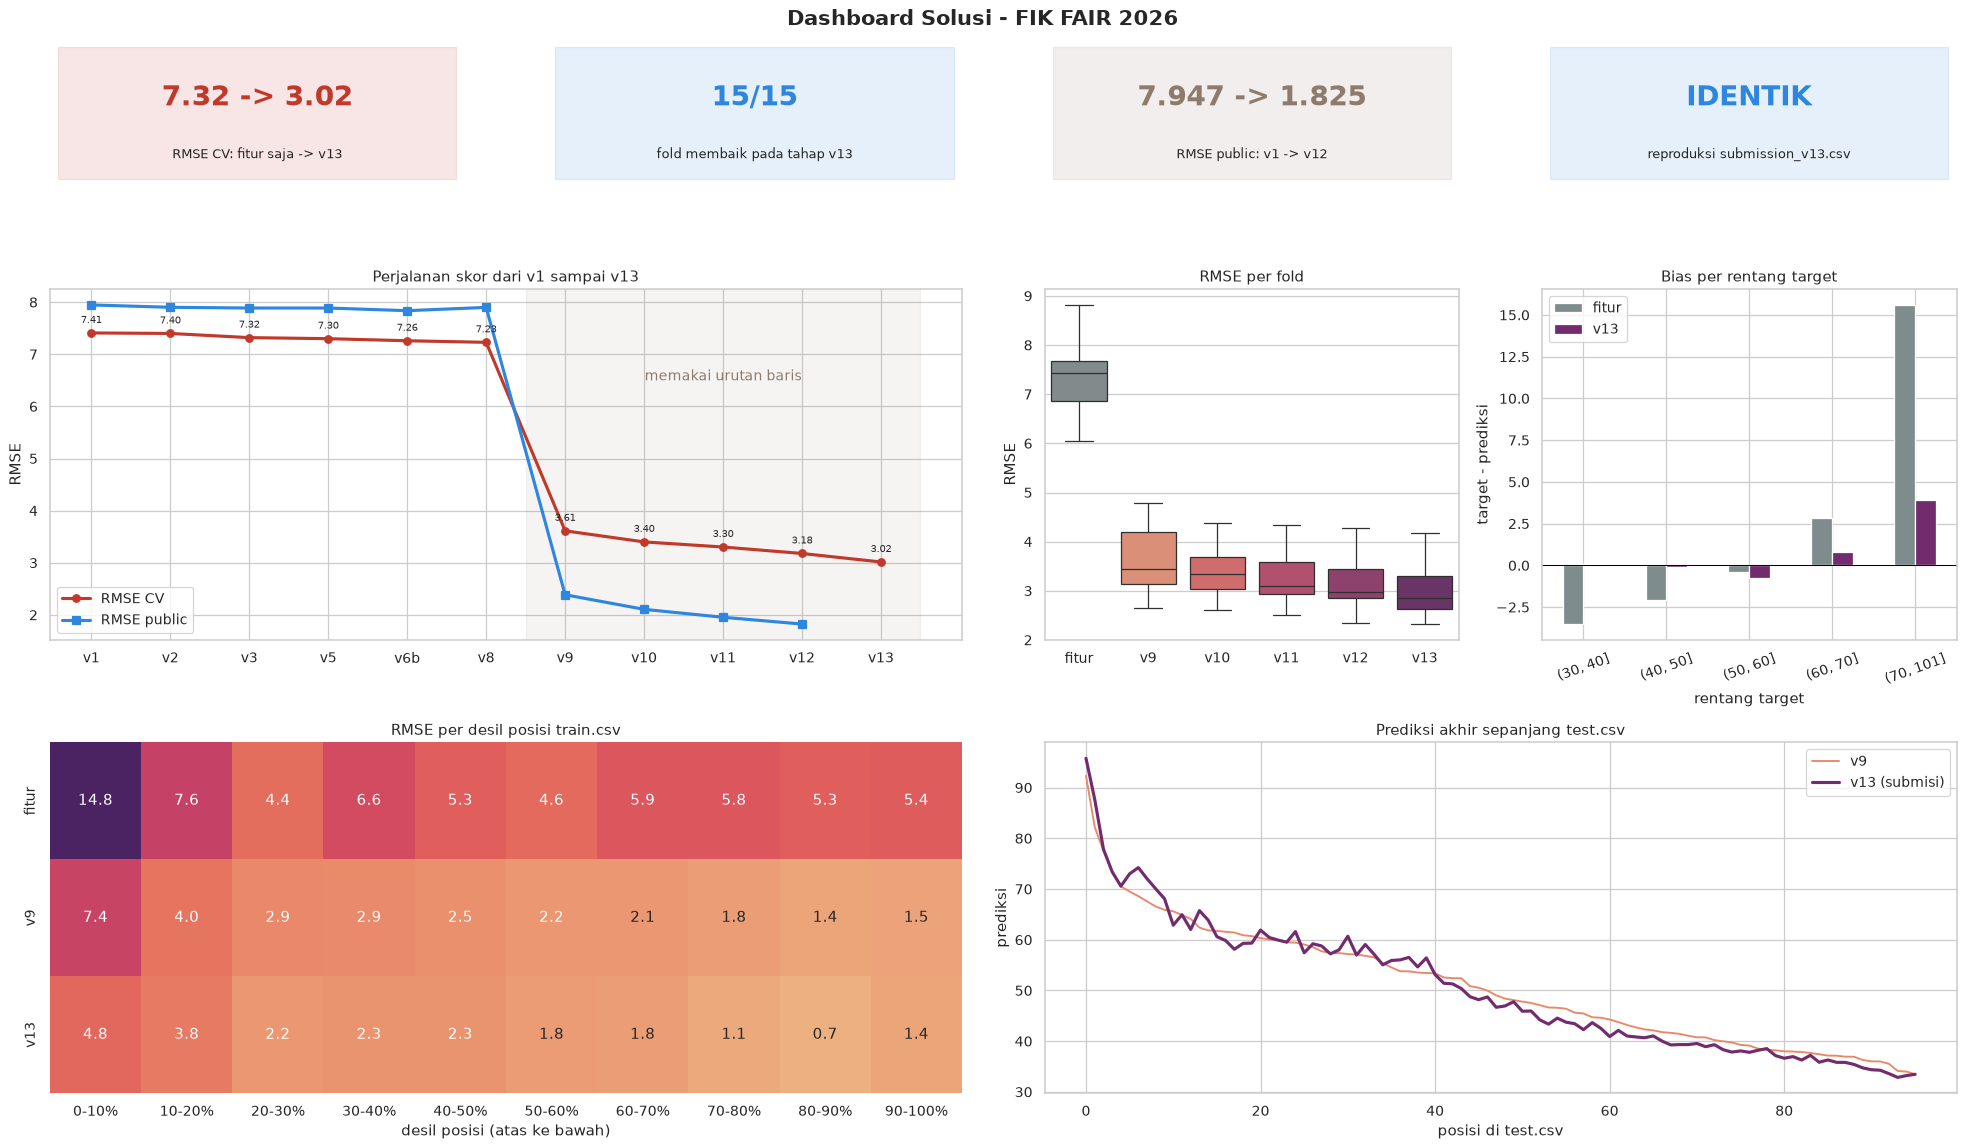

,fitur,v13
bin,,
"(30, 40]",-3.51,0.09
"(40, 50]",-2.08,-0.08
"(50, 60]",-0.38,-0.73
"(60, 70]",2.83,0.83
"(70, 101]",15.60,3.89


In [34]:
JOURNEY = pd.DataFrame({
    'versi' : ['v1', 'v2', 'v3', 'v5', 'v6b', 'v8', 'v9', 'v10', 'v11', 'v12', 'v13'],
    'cv'    : [7.41, 7.40, 7.32, 7.30, 7.26, 7.23] + [s['RMSE sebelumnya'] for s in STAGE_LOG] + [STAGE_LOG[-1]['RMSE tahap']],
    'public': [7.947, 7.902, 7.888, 7.888, 7.837, 7.900, 2.387, 2.107, 1.955, 1.825, np.nan],
})
calib_v13 = pd.DataFrame({'y': y, 'fitur': feature_oof.mean(0), 'v13': v13_oof.mean(0), 'bin': bins}).groupby(
    'bin', observed=True).apply(lambda d: pd.Series({'fitur': (d.y - d.fitur).mean(), 'v13': (d.y - d.v13).mean()}))

fig = plt.figure(figsize=(22, 13))
gs = GridSpec(3, 4, height_ratios=[0.42, 1, 1], figure=fig)
kpi(fig.add_subplot(gs[0, 0]), f'{fold_tab["fitur"].mean():.2f} -> {fold_tab["v13"].mean():.2f}', 'RMSE CV: fitur saja -> v13', CFG.C_ACCENT)
kpi(fig.add_subplot(gs[0, 1]), STAGE_LOG[-1]['fold membaik'], 'fold membaik pada tahap v13', CFG.C_TEST)
kpi(fig.add_subplot(gs[0, 2]), '7.947 -> 1.825', 'RMSE public: v1 -> v12')
kpi(fig.add_subplot(gs[0, 3]), 'IDENTIK' if max_diff < 1e-6 else 'BERBEDA', 'reproduksi submission_v13.csv',
    CFG.C_TEST if max_diff < 1e-6 else CFG.C_ACCENT)

a = fig.add_subplot(gs[1, :2])
a.plot(JOURNEY['versi'], JOURNEY['cv'], marker='o', lw=2.5, color=CFG.C_ACCENT, label='RMSE CV')
a.plot(JOURNEY['versi'], JOURNEY['public'], marker='s', lw=2.5, color=CFG.C_TEST, label='RMSE public')
a.axvspan(5.5, 10.5, color=CFG.C_TRAIN, alpha=0.08)
a.text(8, 6.5, 'memakai urutan baris', ha='center', fontsize=11, color=CFG.C_TRAIN)
for xv, v in zip(JOURNEY['versi'], JOURNEY['cv']):
    a.annotate(f'{v:.2f}', (xv, v), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)
a.set(title='Perjalanan skor dari v1 sampai v13', ylabel='RMSE')
a.legend()
a = fig.add_subplot(gs[1, 2])
sns.boxplot(data=fold_tab, ax=a, palette=[CFG.C_GREY] + list(CFG.STAGE_COLORS.values()))
a.set(title='RMSE per fold', ylabel='RMSE')
a = fig.add_subplot(gs[1, 3])
calib_v13.plot.bar(ax=a, color=[CFG.C_GREY, CFG.STAGE_COLORS['v13']], rot=20)
a.axhline(0, color='black', lw=0.8)
a.set(title='Bias per rentang target', xlabel='rentang target', ylabel='target - prediksi')
a = fig.add_subplot(gs[2, :2])
sns.heatmap(dec_tab[['fitur', 'v9', 'v13']].T, annot=True, fmt='.1f', cmap='flare', ax=a, cbar=False)
a.set(title='RMSE per desil posisi train.csv', xlabel='desil posisi (atas ke bawah)')
a = fig.add_subplot(gs[2, 2:])
a.plot(pos_te, v9_test, color=CFG.STAGE_COLORS['v9'], lw=1.5, label='v9')
a.plot(pos_te, v13_test, color=CFG.STAGE_COLORS['v13'], lw=2.5, label='v13 (submisi)')
a.set(title='Prediksi akhir sepanjang test.csv', xlabel='posisi di test.csv', ylabel='prediksi')
a.legend()
fig.suptitle('Dashboard Solusi - FIK FAIR 2026', fontsize=17, fontweight='bold')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '18_solution_dashboard.png', dpi=120, bbox_inches='tight')
plt.show()
display(calib_v13.round(2))

> ### Insights
>
> Dashboard merangkum cerita solusi. Delapan iterasi berbasis fitur hanya menurunkan RMSE *public* dari 7,947 ke 7,837, sedangkan temuan urutan baris menurunkannya ke 2,387. Empat tahap koreksi berikutnya menurunkan RMSE secara konsisten, baik di CV (3,61 ke 3,02) maupun di *public* (2,387 ke 1,825). Arah perubahan CV dan *public* selalu sama sejak v9, padahal skor *public* tidak pernah dipakai untuk memilih apa pun.
>
> Panel kalibrasi menunjukkan masalah utama lapisan fitur yang terselesaikan. Bias pada baris dengan target di atas 70 turun dari +15,60 menjadi +3,89 poin, dan bias pada rentang 30 sampai 40 turun dari -3,51 menjadi +0,09. Model akhir tidak lagi menyusut ke tengah.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pasca-Analisis <a name="9"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Analisis Kesalahan

Galat *out-of-fold* versi 13 dianalisis per *record* untuk melihat baris mana yang masih sulit, apakah galatnya memiliki arah yang sistematis, dan bagaimana galat tersebar sepanjang berkas.

,record_id,posisi,target,prediksi,galat
43,D0414,43,75.85,65.83,10.02
24,D0175,24,76.30,66.81,9.50
0,D0450,0,100.44,91.82,8.62
22,D0423,22,78.95,70.74,8.21
1,D0410,1,97.38,89.43,7.94
46,D0203,46,57.66,65.54,-7.88
28,D0350,28,77.47,69.68,7.79
68,D0024,68,56.99,64.75,-7.76
39,D0151,39,70.43,62.75,7.67
5,D0205,5,81.71,74.32,7.38


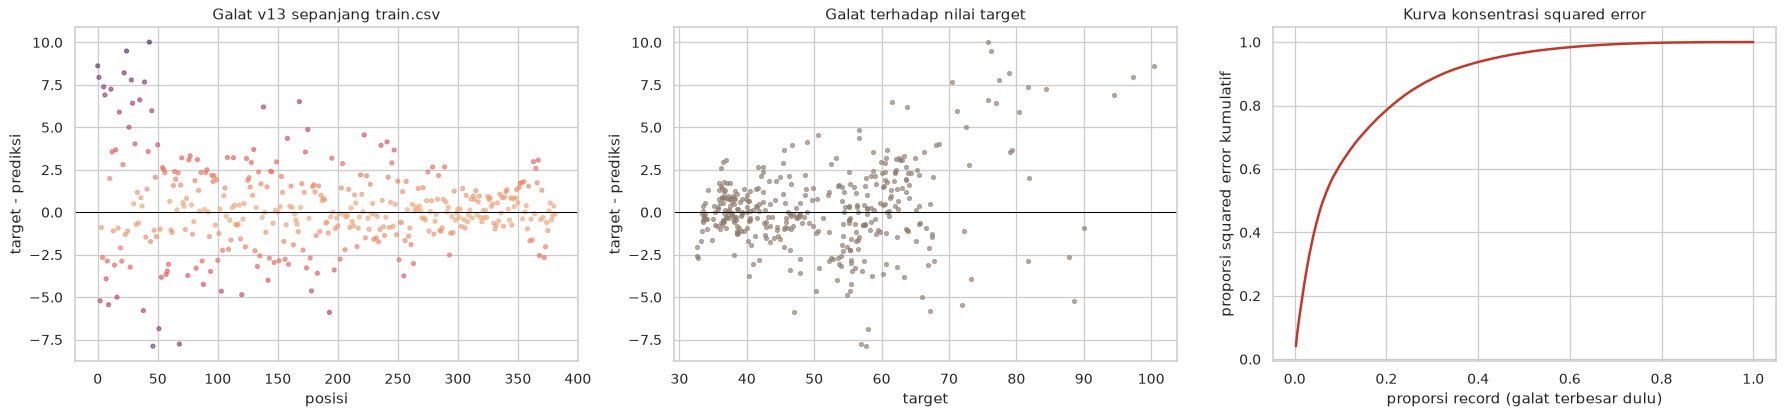

38 baris teratas (10%) menyumbang 35.5% squared error
10 record terburuk menyumbang 28.4% squared error
galat positif (under-predict) pada 38 baris teratas: 21 | negatif: 17


In [35]:
oof13 = v13_oof.mean(0)
err = y - oof13
se = err ** 2
worst = pd.DataFrame({'record_id': train['record_id'], 'posisi': pos_tr, 'target': y, 'prediksi': oof13,
                      'galat': err}).reindex(np.argsort(-np.abs(err))).head(10)
display(worst.round(2))

fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
ax[0].scatter(pos_tr, err, s=10, alpha=0.6, c=np.abs(err), cmap='flare')
ax[0].axhline(0, color='black', lw=0.8)
ax[0].set(title='Galat v13 sepanjang train.csv', xlabel='posisi', ylabel='target - prediksi')
ax[1].scatter(y, err, s=10, alpha=0.6, color=CFG.C_TRAIN)
ax[1].axhline(0, color='black', lw=0.8)
ax[1].set(title='Galat terhadap nilai target', xlabel='target', ylabel='target - prediksi')
ax[2].plot(np.arange(1, len(y) + 1) / len(y), np.cumsum(np.sort(se)[::-1]) / se.sum(), color=CFG.C_ACCENT, lw=2)
ax[2].set(title='Kurva konsentrasi squared error', xlabel='proporsi record (galat terbesar dulu)',
          ylabel='proporsi squared error kumulatif')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '19_error_analysis.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'38 baris teratas (10%) menyumbang {se[:38].sum() / se.sum():.1%} squared error')
print(f'10 record terburuk menyumbang {np.sort(se)[::-1][:10].sum() / se.sum():.1%} squared error')
print(f'galat positif (under-predict) pada 38 baris teratas: {(err[:38] > 0).sum()} | negatif: {(err[:38] < 0).sum()}')

> ### Insights
>
> Galat masih terkonsentrasi. 38 baris teratas berkas (10%) menyumbang 35,5% *squared error*, dan 10 *record* terburuk saja menyumbang 28,4%. Seluruh *record* terburuk berada di 70 baris pertama berkas.
>
> Galat di bagian atas berkas memiliki dua arah: 21 *under-predict* dan 17 *over-predict*. Contohnya D0414 (target 75,85, diprediksi 65,83) dan sebaliknya D0203 (target 57,66, diprediksi 65,54). Koreksi sepihak seperti menaikkan semua prediksi teratas tidak dibenarkan. Yang sulit adalah baris yang targetnya menyimpang dari tetangga di urutan berkas, yaitu deviasi lokal yang sudah terlihat pada EDA.

---

## Simulasi *Public* vs *Private*

*Public leaderboard* hanya dihitung dari sekitar 29 baris. Untuk memahami seberapa besar skor dapat berubah hanya karena pemilihan baris, galat *out-of-fold* versi 13 dipakai untuk mensimulasikan 5.000 berkas *test* berukuran 96 baris, masing-masing dibagi acak menjadi 29 baris *public* dan 67 baris *private* yang saling lepas.

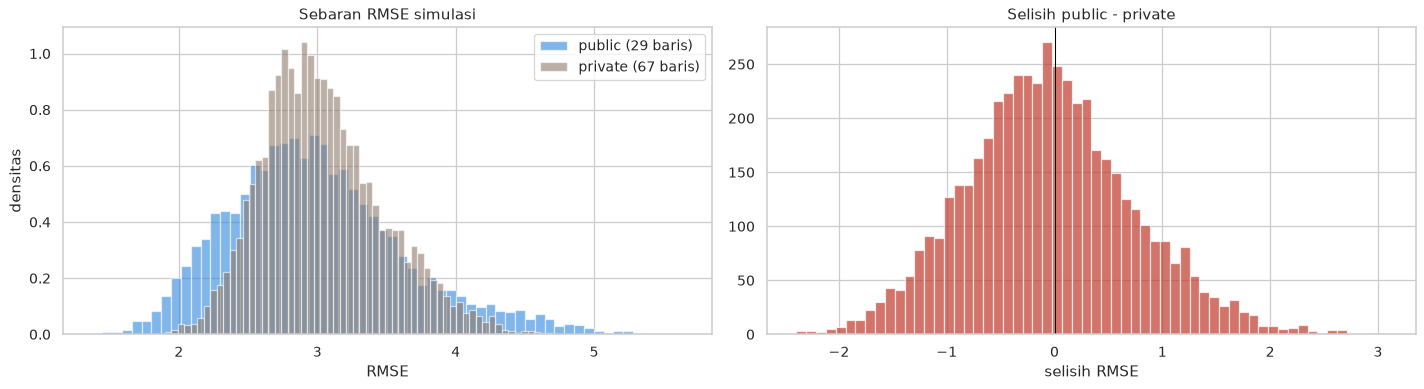

         mean     5%    50%    95%
public   2.99  2.063  2.926  4.223
private  3.04  2.404  2.989  3.844
gap     -0.05 -1.287 -0.078  1.291
P(|public - private| > 0.5): 50.7%


In [36]:
sim_rng = np.random.default_rng(CFG.SEED)
sim = []
for _ in range(5000):
    r = sim_rng.integers(CFG.N_REPEATS)
    rows = sim_rng.choice(len(y), 96, replace=False)
    e2 = (v13_oof[r, rows] - y[rows]) ** 2
    sim.append((np.sqrt(e2[:29].mean()), np.sqrt(e2[29:].mean())))
sim = pd.DataFrame(sim, columns=['public', 'private'])
sim['gap'] = sim['public'] - sim['private']

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
ax[0].hist(sim['public'], bins=60, alpha=0.6, density=True, color=CFG.C_TEST, label='public (29 baris)')
ax[0].hist(sim['private'], bins=60, alpha=0.6, density=True, color=CFG.C_TRAIN, label='private (67 baris)')
ax[0].set(title='Sebaran RMSE simulasi', xlabel='RMSE', ylabel='densitas')
ax[0].legend()
ax[1].hist(sim['gap'], bins=60, color=CFG.C_ACCENT, alpha=0.7)
ax[1].axvline(0, color='black', lw=0.8)
ax[1].set(title='Selisih public - private', xlabel='selisih RMSE')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '20_public_private.png', dpi=120, bbox_inches='tight')
plt.show()
print(sim.describe(percentiles=[0.05, 0.5, 0.95]).T[['mean', '5%', '50%', '95%']].round(3).to_string())
print(f'P(|public - private| > 0.5): {(sim.gap.abs() > 0.5).mean():.1%}')

> ### Insights
>
> Hanya karena pemilihan baris, RMSE 29 baris *public* bervariasi dari 2,06 sampai 4,22 (persentil 5 sampai 95), jauh lebih lebar daripada 67 baris *private* (2,40 sampai 3,84). Separuh simulasi memiliki selisih *public* dan *private* lebih dari 0,5. Dengan variasi sebesar ini, mengoptimalkan skor *public* sama dengan mengoptimalkan *noise*. Karena itu seluruh keputusan diambil dari CV *nested*.
>
> Skor *public* aktual v12 (1,825) berada di bawah rentang simulasi. Ini wajar karena model final dilatih pada seluruh 382 baris, sedangkan simulasi memakai model *out-of-fold* yang hanya melihat 306 baris, dan *learning curve* menunjukkan galat masih turun seiring bertambahnya data. Simulasi lebih tepat dibaca sebagai ukuran ketidakpastian, bukan ramalan skor *private*.

---

### Kelebihan Pendekatan

Solusi ini memadukan dua sumber informasi yang saling melengkapi. *Foundation model* tabular memberi prediksi terbaik yang dapat diperoleh dari fitur dengan hanya 382 baris, tanpa *training* gradien yang rawan *overfitting*. Urutan baris memberi informasi tentang ekor kanan yang tidak terlihat dari fitur. Setiap tahap koreksi bersifat ringan (Ridge dan *Kernel Ridge* di CPU), dipilih melalui seleksi *nested*, dan digabungkan dengan bobot tetap, sehingga peluang *overfitting* terhadap validasi tetap kecil. Mode `INFERENCE` mereproduksi submisi secara identik dalam beberapa menit, dan seluruh angka validasi dihitung ulang di dalam notebook.

---

### Keterbatasan yang Diketahui

Lapisan urutan mengasumsikan bahwa `test.csv` disusun dengan cara yang sama seperti `train.csv`. Asumsi ini didukung kuat oleh dua bukti tidak langsung dan penggunaannya telah dikonfirmasi panitia, namun tidak dapat dibuktikan tanpa label *test*, dan metode ini tidak berlaku untuk data masa depan yang tidak terurut. Tanpa urutan, solusi terbaik berada di sekitar RMSE 7,3. Seleksi *nested* menghilangkan kebocoran pemilihan parameter di dalam *fold*, tetapi katalog kandidat dirancang setelah mempelajari 382 baris yang sama, dan tidak ada data *holdout* lokal yang benar-benar belum tersentuh. Lapisan fitur memakai *pseudo-labelling* transduktif pada fitur *test* (tanpa label), sehingga keseluruhan pipeline tidak bebas *pseudo-label*.

---

### Arah Pengembangan Berikutnya

Galat terbesar terkonsentrasi pada sekitar 10% baris teratas berkas. Arah yang paling menjanjikan adalah model residual yang khusus menangani bagian atas berkas, misalnya *heteroscedastic kernel* dengan varians yang bergantung pada posisi, serta taksiran posisi yang memanfaatkan *foundation model* sebagai pengukur kemiripan, bukan hanya PCA-12. *Learning curve* komponen *kernel* yang masih turun (3,73 pada 143 baris menjadi 3,12 pada 286 baris saat pengembangan) menunjukkan tambahan data berlabel masih akan membantu.

---

### Kepatuhan terhadap Aturan

Hanya dataset resmi yang dipakai. Tidak ada data eksternal, identifikasi entitas asli, rekonstruksi target *test*, maupun *probing leaderboard*. Skor *public* hanya dicatat dan tidak pernah dipakai untuk memilih parameter atau mengubah prediksi per baris. `record_id` tidak diubah. Penggunaan urutan baris diungkapkan secara terbuka dan telah dikonfirmasi panitia pada 4 Oktober 2026. AI/LLM dipakai sebagai alat bantu *coding*, analisis, dan dokumentasi sesuai aturan kompetisi.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Pustaka <a name="10"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Barlow, R. E., Bartholomew, D. J., Bremner, J. M., & Brunk, H. D. (1972). *Statistical Inference under Order Restrictions: The Theory and Application of Isotonic Regression*. Wiley.

Cleveland, W. S. (1979). *Robust Locally Weighted Regression and Smoothing Scatterplots*. Journal of the American Statistical Association, 74(368), 829-836.

Fan, J., & Gijbels, I. (1996). *Local Polynomial Modelling and Its Applications*. Chapman & Hall.

FIK FAIR 2026. (2026). *Data Science Competition FIK FAIR 2026*. Kaggle. https://www.kaggle.com/competitions/data-science-competition-fikfair2026

Hollmann, N., Muller, S., Purucker, L., Krishnakumar, A., Korfer, M., Hoo, S. B., Schirrmeister, R. T., & Hutter, F. (2025). *Accurate predictions on small data with a tabular foundation model*. Nature, 637, 319-326.

Lee, D.-H. (2013). *Pseudo-Label: The Simple and Efficient Semi-Supervised Learning Method for Deep Neural Networks*. ICML Workshop on Challenges in Representation Learning.

Marchenko, V. A., & Pastur, L. A. (1967). *Distribution of eigenvalues for some sets of random matrices*. Mathematics of the USSR-Sbornik, 1(4), 457-483.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, E. (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, 12, 2825-2830.

Qu, J., Holzmuller, D., Varoquaux, G., & Le Morvan, M. (2025). *TabICL: A Tabular Foundation Model for In-Context Learning on Large Data*. ICML 2025. arXiv:2502.05564.

Scholkopf, B., & Smola, A. J. (2002). *Learning with Kernels: Support Vector Machines, Regularization, Optimization, and Beyond*. MIT Press.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Terima Kasih <a name=""></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

**Terima kasih khusus kepada:**

Panitia **Data Science Competition FIK FAIR 2026**, Fakultas Ilmu Komputer UPN "Veteran" Jakarta, yang telah menyediakan dataset dan platform kompetisi yang menantang.